In [1]:
# ============================================================
# BLOCK 1 : ENVIRONMENT SETUP
# EEG Seizure Detection using Pure Machine Learning
# ============================================================

print("=" * 70)
print("EEG SEIZURE DETECTION - PURE MACHINE LEARNING PIPELINE")
print("=" * 70)

# ------------------------------------------------------------
# Install Required Packages
# ------------------------------------------------------------

!pip -q install antropy
!pip -q install PyWavelets
!pip -q install nolds
!pip -q install xgboost
!pip -q install lightgbm
!pip -q install catboost
!pip -q install boruta
!pip -q install optuna
!pip -q install shap
!pip -q install missingno
!pip -q install tqdm
!pip -q install joblib

print("\n✓ All required packages installed successfully.")
print("=" * 70)

EEG SEIZURE DETECTION - PURE MACHINE LEARNING PIPELINE
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 8.0 MB/s eta 0:00:00

✓ All required packages installed successfully.


In [2]:
# ============================================================
# BLOCK 2 : IMPORTS & REPRODUCIBILITY
# ============================================================

print("=" * 70)
print("IMPORTING LIBRARIES & SETTING REPRODUCIBILITY")
print("=" * 70)

# ------------------------------------------------------------
# Standard Libraries
# ------------------------------------------------------------

import os
import gc
import random
import warnings
import joblib
from tqdm import tqdm

# ------------------------------------------------------------
# Numerical Computing
# ------------------------------------------------------------

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# ------------------------------------------------------------
# Signal Processing
# ------------------------------------------------------------

from scipy.signal import (
    butter,
    filtfilt,
    iirnotch,
    welch
)

from scipy.stats import (
    skew,
    kurtosis
)

import pywt
import antropy as ant
import nolds

# ------------------------------------------------------------
# Feature Selection
# ------------------------------------------------------------

from boruta import BorutaPy

from sklearn.feature_selection import (
    mutual_info_classif
)

# ------------------------------------------------------------
# Data Preprocessing
# ------------------------------------------------------------

from sklearn.preprocessing import (
    RobustScaler
)

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

# ------------------------------------------------------------
# Machine Learning Models
# ------------------------------------------------------------

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Hyperparameter Optimization
# ------------------------------------------------------------

import optuna

# ------------------------------------------------------------
# Explainability
# ------------------------------------------------------------

import shap

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_curve,
    precision_recall_curve,
    auc
)

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Plot Configuration
# ------------------------------------------------------------

plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 12

sns.set_style("whitegrid")

# ------------------------------------------------------------
# Dataset Configuration
# ------------------------------------------------------------

DATASET_PATH = "/kaggle/input/datasets/masahirogotoh/mit-chb-processed"

SAMPLING_RATE = 256
WINDOW_LENGTH = 2048
N_CHANNELS = 18

print(f"Dataset Path   : {DATASET_PATH}")
print(f"Sampling Rate  : {SAMPLING_RATE} Hz")
print(f"Window Length  : {WINDOW_LENGTH}")
print(f"EEG Channels   : {N_CHANNELS}")
print(f"Random Seed    : {SEED}")

print("=" * 70)
print("INITIALIZATION COMPLETED")
print("=" * 70)

IMPORTING LIBRARIES & SETTING REPRODUCIBILITY
Dataset Path   : /kaggle/input/datasets/masahirogotoh/mit-chb-processed
Sampling Rate  : 256 Hz
Window Length  : 2048
EEG Channels   : 18
Random Seed    : 42
INITIALIZATION COMPLETED


In [3]:
# ============================================================
# BLOCK 3 : LOAD EEG DATASET
# ============================================================

print("=" * 70)
print("LOADING EEG DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Dataset Files
# ------------------------------------------------------------

SIGNAL_PATH = os.path.join(DATASET_PATH, "signal_samples.npy")
LABEL_PATH  = os.path.join(DATASET_PATH, "is_sz.npy")

# ------------------------------------------------------------
# Verify Files
# ------------------------------------------------------------

assert os.path.exists(SIGNAL_PATH), f"File not found: {SIGNAL_PATH}"
assert os.path.exists(LABEL_PATH),  f"File not found: {LABEL_PATH}"

print("✓ Dataset files found.")

# ------------------------------------------------------------
# Load Dataset
# ------------------------------------------------------------

signals = np.load(SIGNAL_PATH)
labels  = np.load(LABEL_PATH)

print("\nDataset Loaded Successfully.")

print("=" * 70)
print(f"Signals Shape : {signals.shape}")
print(f"Labels Shape  : {labels.shape}")
print("=" * 70)

# ------------------------------------------------------------
# Basic Dataset Information
# ------------------------------------------------------------

print(f"Total EEG Windows : {len(signals):,}")
print(f"EEG Channels      : {signals.shape[1]}")
print(f"Samples / Window  : {signals.shape[2]}")

print("=" * 70)

# ------------------------------------------------------------
# Memory Usage
# ------------------------------------------------------------

memory_mb = signals.nbytes / (1024 ** 2)

print(f"Dataset Memory : {memory_mb:.2f} MB")

print("=" * 70)

LOADING EEG DATASET
✓ Dataset files found.

Dataset Loaded Successfully.
Signals Shape : (9505, 18, 2048)
Labels Shape  : (9505,)
Total EEG Windows : 9,505
EEG Channels      : 18
Samples / Window  : 2048
Dataset Memory : 1336.64 MB


In [4]:
# ============================================================
# BLOCK 4 : DATASET VERIFICATION
# ============================================================

print("=" * 70)
print("DATASET VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# Dataset Information
# ------------------------------------------------------------

print(f"Signal Shape       : {signals.shape}")
print(f"Label Shape        : {labels.shape}")
print(f"Signal Data Type   : {signals.dtype}")
print(f"Label Data Type    : {labels.dtype}")

print("=" * 70)

# ------------------------------------------------------------
# Missing Values
# ------------------------------------------------------------

signal_nan = np.isnan(signals).sum()
label_nan = np.isnan(labels).sum()

print(f"Missing Values (Signals): {signal_nan}")
print(f"Missing Values (Labels) : {label_nan}")

print("=" * 70)

# ------------------------------------------------------------
# Infinite Values
# ------------------------------------------------------------

signal_inf = np.isinf(signals).sum()
label_inf = np.isinf(labels).sum()

print(f"Infinite Values (Signals): {signal_inf}")
print(f"Infinite Values (Labels) : {label_inf}")

print("=" * 70)

# ------------------------------------------------------------
# Label Distribution
# ------------------------------------------------------------

unique_labels, counts = np.unique(labels, return_counts=True)

print("Class Distribution")

for cls, cnt in zip(unique_labels, counts):
    percentage = (cnt / len(labels)) * 100
    print(f"Class {cls} : {cnt} ({percentage:.2f}%)")

print("=" * 70)

# ------------------------------------------------------------
# Signal Statistics
# ------------------------------------------------------------

print("Signal Statistics")

print(f"Minimum Value : {signals.min():.4f}")
print(f"Maximum Value : {signals.max():.4f}")
print(f"Mean          : {signals.mean():.4f}")
print(f"Std           : {signals.std():.4f}")

print("=" * 70)

# ------------------------------------------------------------
# Duplicate Windows
# ------------------------------------------------------------

flat_signals = signals.reshape(signals.shape[0], -1)

duplicate_windows = (
    pd.DataFrame(flat_signals)
      .duplicated()
      .sum()
)

print(f"Duplicate EEG Windows : {duplicate_windows}")

print("=" * 70)

# ------------------------------------------------------------
# Memory Usage
# ------------------------------------------------------------

memory_gb = signals.nbytes / (1024**3)

print(f"Memory Usage : {memory_gb:.2f} GB")

print("=" * 70)
print("DATASET VERIFICATION COMPLETED")
print("=" * 70)

DATASET VERIFICATION
Signal Shape       : (9505, 18, 2048)
Label Shape        : (9505,)
Signal Data Type   : float32
Label Data Type    : bool
Missing Values (Signals): 0
Missing Values (Labels) : 0
Infinite Values (Signals): 0
Infinite Values (Labels) : 0
Class Distribution
Class False : 6924 (72.85%)
Class True : 2581 (27.15%)
Signal Statistics
Minimum Value : -4023.9316
Maximum Value : 4563.1260
Mean          : 0.2317
Std           : 82.4455
Duplicate EEG Windows : 3
Memory Usage : 1.31 GB
DATASET VERIFICATION COMPLETED


EXPLORATORY DATA ANALYSIS


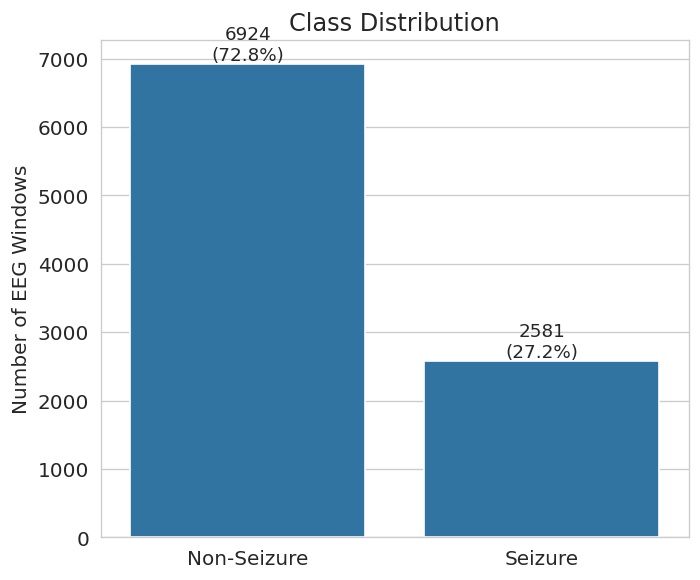

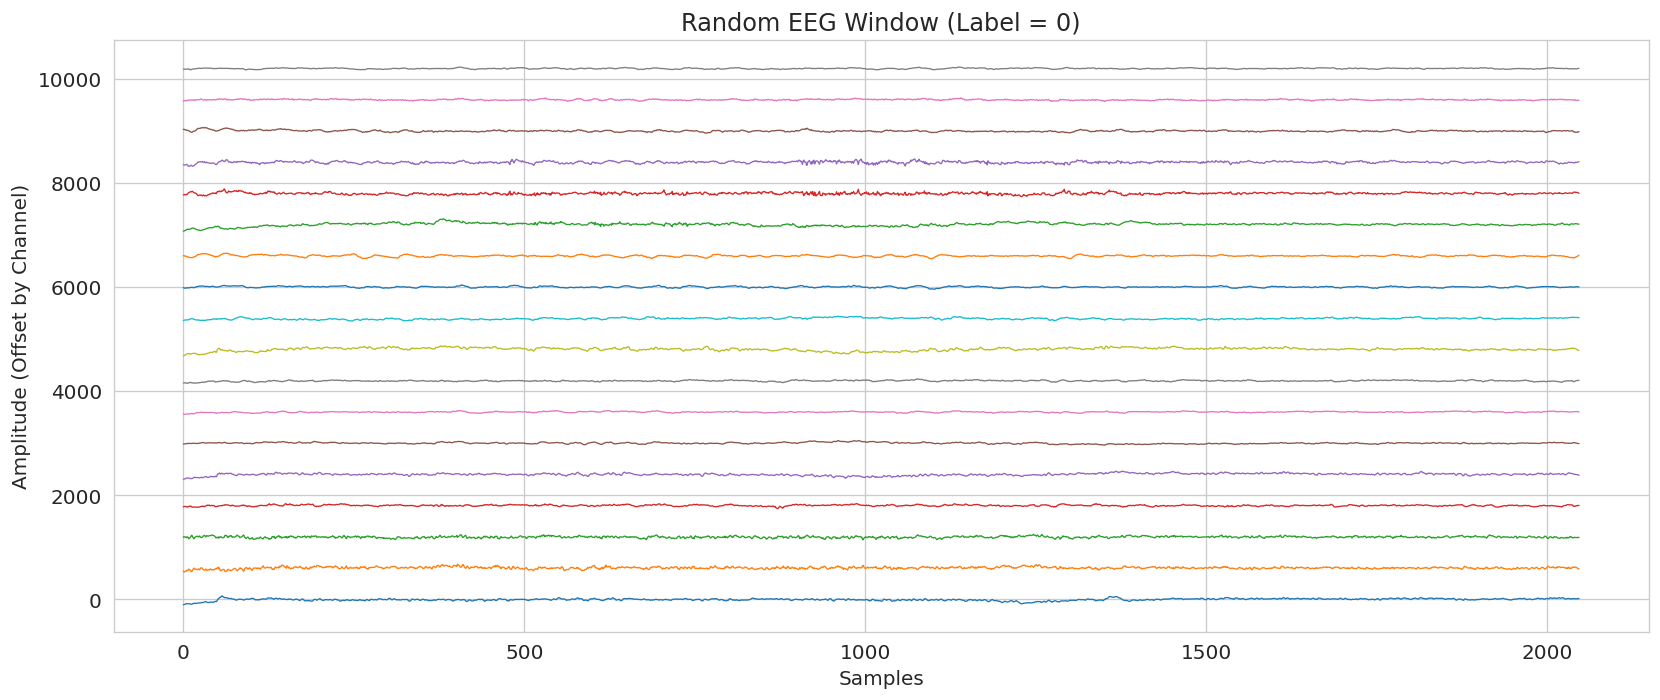

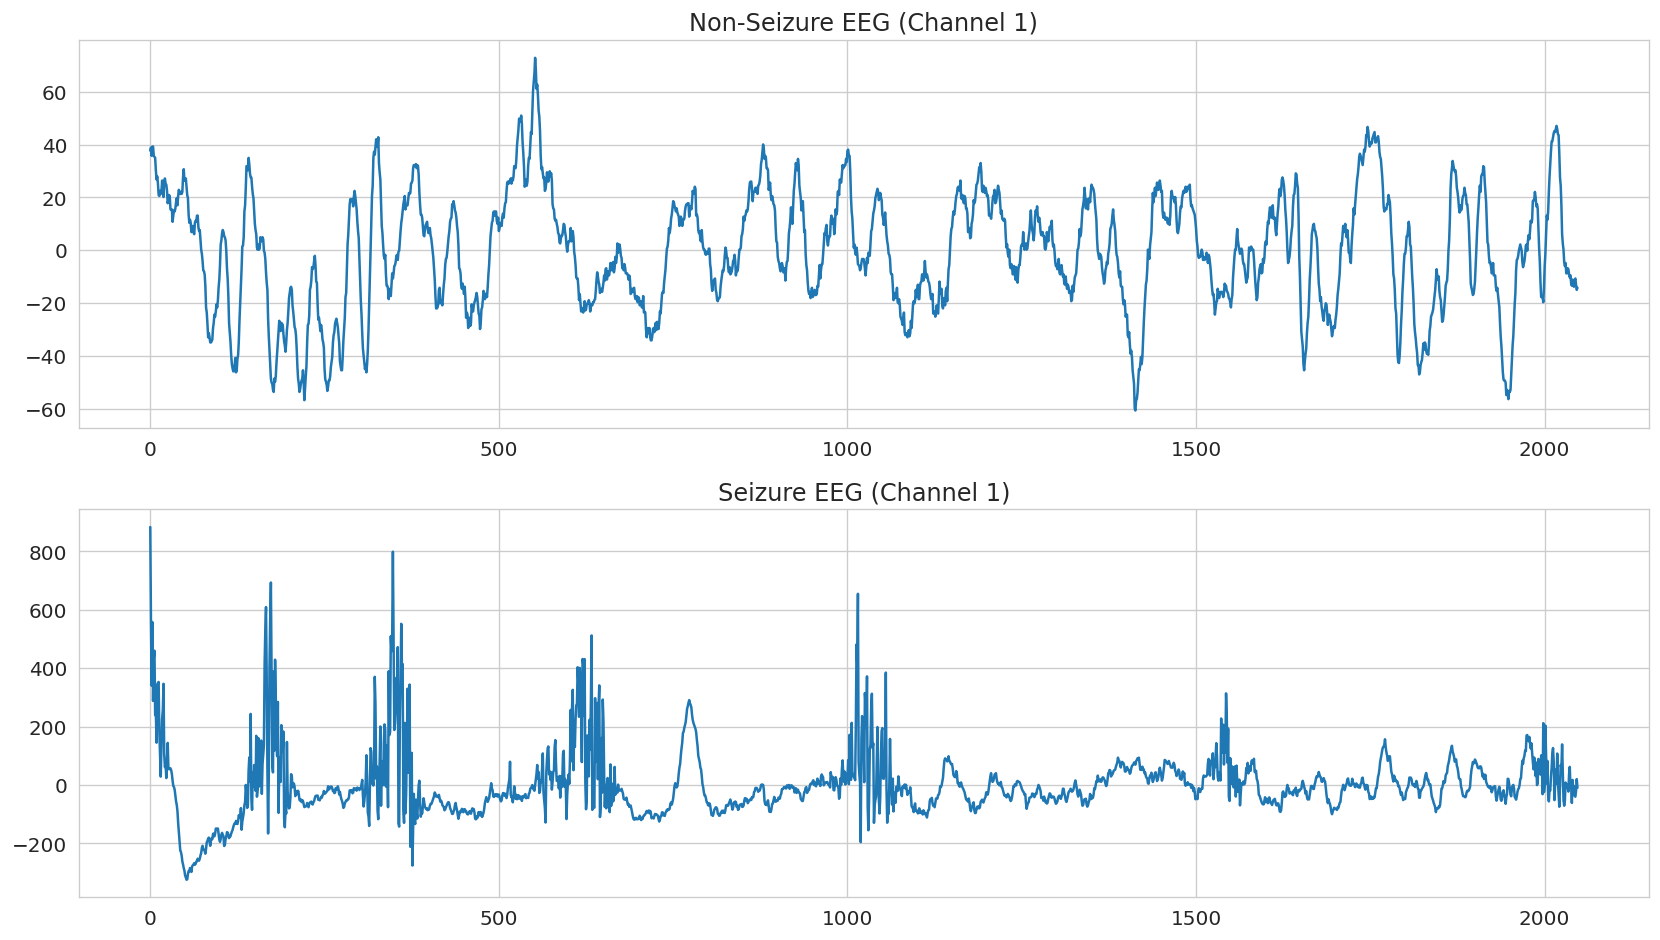

EDA COMPLETED


In [5]:
# ============================================================
# BLOCK 5 : EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Convert Labels to Integer
# ------------------------------------------------------------

labels = labels.astype(np.uint8)

# ------------------------------------------------------------
# Class Distribution
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

class_counts = pd.Series(labels).value_counts().sort_index()

ax = sns.barplot(
    x=["Non-Seizure", "Seizure"],
    y=class_counts.values
)

for i, count in enumerate(class_counts.values):
    percentage = (count / len(labels)) * 100
    ax.text(
        i,
        count + 50,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        fontsize=11
    )

plt.title("Class Distribution")
plt.ylabel("Number of EEG Windows")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Random EEG Window
# ------------------------------------------------------------

random_index = np.random.randint(0, len(signals))

plt.figure(figsize=(14, 6))

for ch in range(signals.shape[1]):
    plt.plot(
        signals[random_index, ch] + ch * 600,
        linewidth=0.8
    )

plt.title(f"Random EEG Window (Label = {labels[random_index]})")
plt.xlabel("Samples")
plt.ylabel("Amplitude (Offset by Channel)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Example Seizure vs Non-Seizure
# ------------------------------------------------------------

non_idx = np.where(labels == 0)[0][0]
sz_idx  = np.where(labels == 1)[0][0]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(signals[non_idx, 0])
axes[0].set_title("Non-Seizure EEG (Channel 1)")

axes[1].plot(signals[sz_idx, 0])
axes[1].set_title("Seizure EEG (Channel 1)")

plt.tight_layout()
plt.show()

print("=" * 70)
print("EDA COMPLETED")
print("=" * 70)

In [6]:
# ============================================================
# BLOCK 6 : TRAIN / VALIDATION / TEST SPLIT
# ============================================================

print("=" * 70)
print("CREATING TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Convert Labels
# ------------------------------------------------------------

labels = labels.astype(np.uint8)

# ------------------------------------------------------------
# First Split
# Train : 70%
# Temp  : 30%
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(

    signals,
    labels,

    test_size=0.30,

    stratify=labels,

    random_state=SEED,

    shuffle=True

)

# ------------------------------------------------------------
# Second Split
# Validation : 15%
# Test       : 15%
# ------------------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    stratify=y_temp,

    random_state=SEED,

    shuffle=True

)

print("=" * 70)
print("DATA SPLIT COMPLETED")
print("=" * 70)

print(f"Training Samples   : {len(X_train):,}")
print(f"Validation Samples : {len(X_val):,}")
print(f"Test Samples       : {len(X_test):,}")

print("=" * 70)

print("Class Distribution")

print(f"Train      : {np.bincount(y_train)}")

print(f"Validation : {np.bincount(y_val)}")

print(f"Test       : {np.bincount(y_test)}")

print("=" * 70)

CREATING TRAIN / VALIDATION / TEST SPLIT
DATA SPLIT COMPLETED
Training Samples   : 6,653
Validation Samples : 1,426
Test Samples       : 1,426
Class Distribution
Train      : [4846 1807]
Validation : [1039  387]
Test       : [1039  387]


In [7]:
# ============================================================
# BLOCK 7 : EEG BATCH GENERATOR
# ============================================================

print("=" * 70)
print("EEG BATCH GENERATOR")
print("=" * 70)

class EEGDataGenerator:

    def __init__(self, signals, labels, batch_size=64):

        self.signals = signals
        self.labels = labels
        self.batch_size = batch_size
        self.n_samples = len(signals)

    def __len__(self):

        return int(np.ceil(self.n_samples / self.batch_size))

    def __iter__(self):

        for start in range(0, self.n_samples, self.batch_size):

            end = min(start + self.batch_size, self.n_samples)

            yield (
                self.signals[start:end],
                self.labels[start:end]
            )

print("Generator Class Created")

print("=" * 70)

EEG BATCH GENERATOR
Generator Class Created


In [8]:
# ============================================================
# BLOCK 9 : VERIFY GENERATOR
# ============================================================
# ============================================================
# CREATE GENERATORS
# ============================================================

train_generator = EEGDataGenerator(
    X_train,
    y_train,
    batch_size=64
)

val_generator = EEGDataGenerator(
    X_val,
    y_val,
    batch_size=64
)

test_generator = EEGDataGenerator(
    X_test,
    y_test,
    batch_size=64
)

print("Train batches :", len(train_generator))
print("Validation batches :", len(val_generator))
print("Test batches :", len(test_generator))
print("=" * 70)
print("VERIFYING GENERATOR")
print("=" * 70)

X_batch, y_batch = next(iter(train_generator))

print(f"Batch Shape : {X_batch.shape}")
print(f"Label Shape : {y_batch.shape}")

print()

print("Batch Label Distribution")

unique, counts = np.unique(y_batch, return_counts=True)

for u, c in zip(unique, counts):
    print(f"Class {u} : {c}")

print("=" * 70)

Train batches : 104
Validation batches : 23
Test batches : 23
VERIFYING GENERATOR
Batch Shape : (64, 18, 2048)
Label Shape : (64,)

Batch Label Distribution
Class 0 : 50
Class 1 : 14


In [9]:
# ============================================================
# BLOCK 10 : SIGNAL PREPROCESSING FUNCTIONS
# ============================================================

print("=" * 70)
print("EEG SIGNAL PREPROCESSING")
print("=" * 70)

from scipy.signal import butter, filtfilt, iirnotch

# ------------------------------------------------------------
# Band-pass Filter
# ------------------------------------------------------------

def bandpass_filter(signal,
                    lowcut=0.5,
                    highcut=40,
                    fs=SAMPLING_RATE,
                    order=4):

    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        order,
        [low, high],
        btype="band"
    )

    return filtfilt(b, a, signal)


# ------------------------------------------------------------
# Notch Filter
# ------------------------------------------------------------

def notch_filter(signal,
                 freq=50,
                 fs=SAMPLING_RATE,
                 quality=30):

    b, a = iirnotch(
        freq,
        quality,
        fs
    )

    return filtfilt(b, a, signal)


# ------------------------------------------------------------
# Z-score Normalization
# ------------------------------------------------------------

def zscore_normalize(signal):

    mean = np.mean(signal)

    std = np.std(signal)

    if std == 0:
        return signal

    return (signal - mean) / std


# ------------------------------------------------------------
# Complete Preprocessing
# ------------------------------------------------------------

def preprocess_window(window):

    processed = np.zeros_like(window)

    for ch in range(window.shape[0]):

        x = window[ch]

        x = bandpass_filter(x)

        x = notch_filter(x)

        x = zscore_normalize(x)

        processed[ch] = x

    return processed

print("✓ Preprocessing Functions Ready")

print("=" * 70)

EEG SIGNAL PREPROCESSING
✓ Preprocessing Functions Ready


In [10]:
# ============================================================
# BLOCK 11 : VERIFY PREPROCESSING
# ============================================================

print("=" * 70)
print("VERIFYING PREPROCESSING")
print("=" * 70)

sample = X_train[0]

processed = preprocess_window(sample)

print("Original Shape :", sample.shape)
print("Processed Shape:", processed.shape)

print()

print("Original Mean :", sample.mean())
print("Processed Mean:", processed.mean())

print()

print("Original Std :", sample.std())
print("Processed Std:", processed.std())

print("=" * 70)

VERIFYING PREPROCESSING
Original Shape : (18, 2048)
Processed Shape: (18, 2048)

Original Mean : 0.5556721
Processed Mean: 7.3729706e-10

Original Std : 96.482864
Processed Std: 1.0


VISUALIZING PREPROCESSING


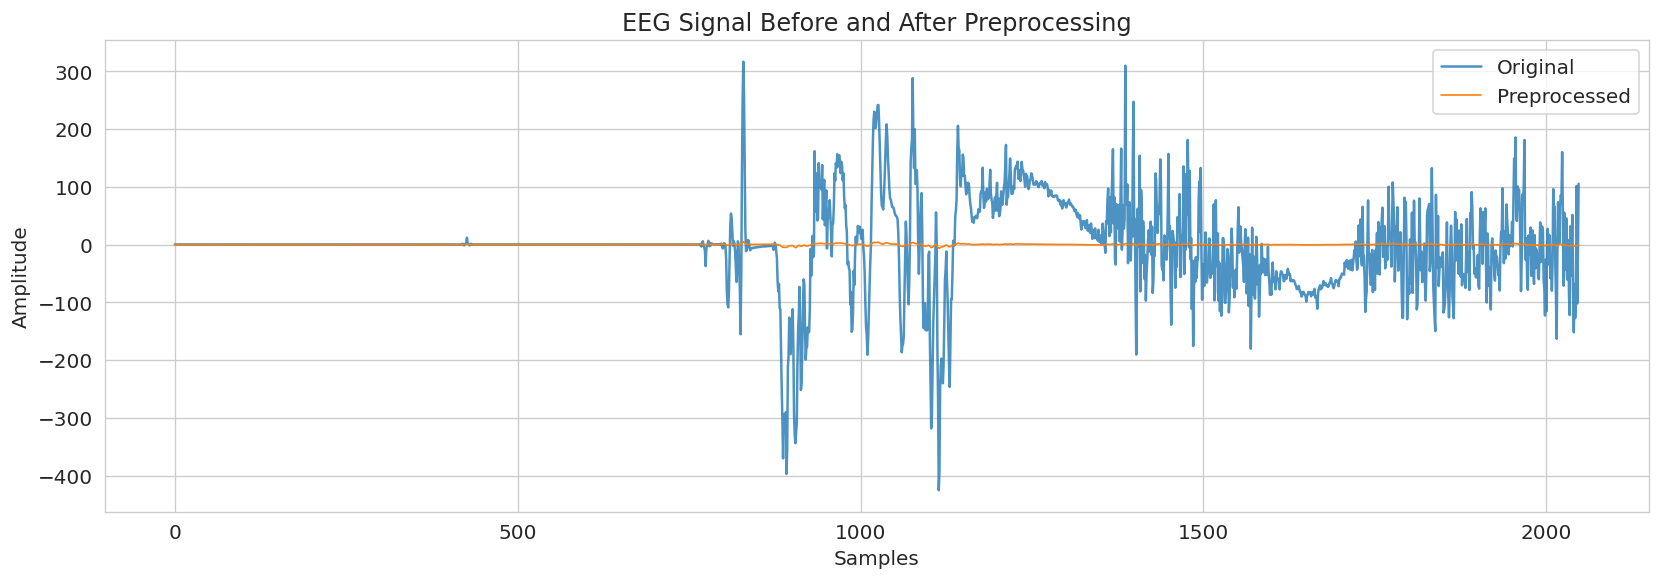

In [11]:
# ============================================================
# BLOCK 12 : VISUALIZE PREPROCESSING
# ============================================================

print("=" * 70)
print("VISUALIZING PREPROCESSING")
print("=" * 70)

channel = 0

plt.figure(figsize=(14,5))

plt.plot(
    sample[channel],
    label="Original",
    alpha=0.8
)

plt.plot(
    processed[channel],
    label="Preprocessed",
    linewidth=1
)

plt.title("EEG Signal Before and After Preprocessing")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.legend()

plt.tight_layout()

plt.show()

print("=" * 70)

In [12]:
# ============================================================
# BLOCK 13 : TIME-DOMAIN FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("TIME-DOMAIN FEATURE EXTRACTION")
print("=" * 70)

from scipy.stats import skew, kurtosis


# ------------------------------------------------------------
# Hjorth Parameters
# ------------------------------------------------------------

def hjorth_parameters(signal):

    first_derivative = np.diff(signal)
    second_derivative = np.diff(first_derivative)

    activity = np.var(signal)

    mobility = np.sqrt(
        np.var(first_derivative) / (activity + 1e-10)
    )

    complexity = np.sqrt(
        np.var(second_derivative) /
        (np.var(first_derivative) + 1e-10)
    ) / (mobility + 1e-10)

    return activity, mobility, complexity


# ------------------------------------------------------------
# Zero Crossing Rate
# ------------------------------------------------------------

def zero_crossing_rate(signal):

    return np.sum(np.diff(np.sign(signal)) != 0)


# ------------------------------------------------------------
# Time Feature Extraction
# ------------------------------------------------------------

def extract_time_features(signal):

    activity, mobility, complexity = hjorth_parameters(signal)

    features = [

        np.mean(signal),

        np.std(signal),

        np.var(signal),

        np.sqrt(np.mean(signal ** 2)),      # RMS

        np.median(signal),

        np.max(signal),

        np.min(signal),

        np.ptp(signal),                     # Peak-to-Peak

        skew(signal),

        kurtosis(signal),

        zero_crossing_rate(signal),

        activity,

        mobility,

        complexity

    ]

    return features

print("✓ Time Feature Extractor Ready")

print("=" * 70)

TIME-DOMAIN FEATURE EXTRACTION
✓ Time Feature Extractor Ready


In [13]:
# ============================================================
# BLOCK 14 : VERIFY TIME FEATURES
# ============================================================

print("=" * 70)
print("VERIFYING TIME FEATURES")
print("=" * 70)

sample_channel = processed[0]

time_features = extract_time_features(sample_channel)

print(f"Number of Time Features : {len(time_features)}")

feature_names = [

    "Mean",
    "Std",
    "Variance",
    "RMS",
    "Median",
    "Maximum",
    "Minimum",
    "Peak-to-Peak",
    "Skewness",
    "Kurtosis",
    "Zero Crossing Rate",
    "Hjorth Activity",
    "Hjorth Mobility",
    "Hjorth Complexity"

]

for name, value in zip(feature_names, time_features):

    print(f"{name:<22}: {value:.5f}")

print("=" * 70)

VERIFYING TIME FEATURES
Number of Time Features : 14
Mean                  : -0.00000
Std                   : 1.00000
Variance              : 1.00000
RMS                   : 1.00000
Median                : 0.02962
Maximum               : 4.96485
Minimum               : -6.21638
Peak-to-Peak          : 11.18122
Skewness              : -1.22112
Kurtosis              : 8.21180
Zero Crossing Rate    : 120.00000
Hjorth Activity       : 1.00000
Hjorth Mobility       : 0.29187
Hjorth Complexity     : 2.23737


In [14]:
# ============================================================
# BLOCK 15 : OPTIMIZED FREQUENCY-DOMAIN FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("OPTIMIZED FREQUENCY-DOMAIN FEATURE EXTRACTION")
print("=" * 70)

from scipy.signal import welch

# ------------------------------------------------------------
# EEG Frequency Bands (Hz)
# ------------------------------------------------------------

EEG_BANDS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta":  (13, 30),
    "gamma": (30, 40)
}


# ------------------------------------------------------------
# Band Power
# ------------------------------------------------------------

def band_power(freqs, psd, low, high):

    mask = (freqs >= low) & (freqs <= high)

    if not np.any(mask):
        return 0.0

    return np.trapezoid(psd[mask], freqs[mask])


# ------------------------------------------------------------
# Frequency Feature Extraction
# ------------------------------------------------------------

def extract_frequency_features(signal):

    # Compute PSD only once
    freqs, psd = welch(
        signal,
        fs=SAMPLING_RATE,
        window="hann",
        nperseg=256,
        noverlap=128,
        detrend="constant",
        scaling="density"
    )

    total_power = np.trapezoid(psd, freqs) + 1e-10

    # --------------------------------------------------------
    # Absolute Band Powers
    # --------------------------------------------------------

    band_powers = np.array([
        band_power(freqs, psd, low, high)
        for low, high in EEG_BANDS.values()
    ], dtype=np.float32)

    # --------------------------------------------------------
    # Relative Band Powers
    # --------------------------------------------------------

    relative_powers = band_powers / total_power

    # --------------------------------------------------------
    # Peak Frequency
    # --------------------------------------------------------

    peak_frequency = freqs[np.argmax(psd)]

    # --------------------------------------------------------
    # Mean Frequency
    # --------------------------------------------------------

    mean_frequency = np.sum(freqs * psd) / np.sum(psd)

    # --------------------------------------------------------
    # Spectral Entropy
    # --------------------------------------------------------

    psd_norm = psd / (np.sum(psd) + 1e-10)

    spectral_entropy = -np.sum(
        psd_norm * np.log2(psd_norm + 1e-12)
    )

    # --------------------------------------------------------
    # Final Feature Vector
    # --------------------------------------------------------

    features = np.concatenate([
        band_powers,
        relative_powers,
        np.array([
            peak_frequency,
            mean_frequency,
            spectral_entropy
        ], dtype=np.float32)
    ])

    return features.astype(np.float32)


print("✓ Optimized Frequency Feature Extractor Ready")
print("=" * 70)

OPTIMIZED FREQUENCY-DOMAIN FEATURE EXTRACTION
✓ Optimized Frequency Feature Extractor Ready


In [15]:
# ============================================================
# BLOCK 16 : VERIFY FREQUENCY FEATURES
# ============================================================

print("=" * 70)
print("VERIFYING FREQUENCY FEATURES")
print("=" * 70)

frequency_features = extract_frequency_features(processed[0])

feature_names = [

    "Delta Power",
    "Theta Power",
    "Alpha Power",
    "Beta Power",
    "Gamma Power",

    "Relative Delta",
    "Relative Theta",
    "Relative Alpha",
    "Relative Beta",
    "Relative Gamma",

    "Peak Frequency",
    "Mean Frequency",
    "Spectral Entropy"

]

print(f"Number of Frequency Features : {len(frequency_features)}")

print()

for name, value in zip(feature_names, frequency_features):

    print(f"{name:<20}: {value:.5f}")

print("=" * 70)

VERIFYING FREQUENCY FEATURES
Number of Frequency Features : 13

Delta Power         : 0.45101
Theta Power         : 0.15610
Alpha Power         : 0.10339
Beta Power          : 0.16882
Gamma Power         : 0.03748
Relative Delta      : 0.43793
Relative Theta      : 0.15157
Relative Alpha      : 0.10039
Relative Beta       : 0.16392
Relative Gamma      : 0.03639
Peak Frequency      : 2.00000
Mean Frequency      : 7.48651
Spectral Entropy    : 4.19778


In [16]:
# ============================================================
# BLOCK 17 : OPTIMIZED WAVELET FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("OPTIMIZED WAVELET FEATURE EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# Wavelet Feature Extraction
# ------------------------------------------------------------

def extract_wavelet_features(signal,
                             wavelet="db4",
                             level=3):
    """
    Extract wavelet-based features from one EEG channel.

    Features:
    1. Approximation Energy
    2. Detail-3 Energy
    3. Detail-2 Energy
    4. Detail-1 Energy
    5. Relative Approximation Energy
    6. Relative Detail-3 Energy
    7. Relative Detail-2 Energy
    8. Relative Detail-1 Energy
    9. Wavelet Entropy
    """

    # Discrete Wavelet Transform
    coeffs = pywt.wavedec(
        signal,
        wavelet=wavelet,
        level=level,
        mode="symmetric"
    )

    # Energy of each coefficient
    energies = np.array(
        [np.sum(c * c) for c in coeffs],
        dtype=np.float32
    )

    total_energy = energies.sum() + 1e-10

    # Relative energies
    relative = energies / total_energy

    # Wavelet entropy
    entropy = -np.sum(
        relative * np.log2(relative + 1e-12)
    )

    # Final feature vector
    features = np.concatenate([
        energies,
        relative,
        np.array([entropy], dtype=np.float32)
    ])

    return features.astype(np.float32)

print("✓ Optimized Wavelet Feature Extractor Ready")
print("=" * 70)

OPTIMIZED WAVELET FEATURE EXTRACTION
✓ Optimized Wavelet Feature Extractor Ready


In [17]:
# ============================================================
# BLOCK 18 : VERIFY WAVELET FEATURES
# ============================================================

print("=" * 70)
print("VERIFYING WAVELET FEATURES")
print("=" * 70)

wavelet_features = extract_wavelet_features(processed[0])

feature_names = [

    "Approximation Energy",
    "Detail Level-3 Energy",
    "Detail Level-2 Energy",
    "Detail Level-1 Energy",

    "Relative Approximation",
    "Relative Detail-3",
    "Relative Detail-2",
    "Relative Detail-1",

    "Wavelet Entropy"

]

print(f"Number of Wavelet Features : {len(wavelet_features)}")

print()

for name, value in zip(feature_names, wavelet_features):

    print(f"{name:<28}: {value:.5f}")

print("=" * 70)

VERIFYING WAVELET FEATURES
Number of Wavelet Features : 9

Approximation Energy        : 1665.30872
Detail Level-3 Energy       : 318.64105
Detail Level-2 Energy       : 70.19746
Detail Level-1 Energy       : 2.61495
Relative Approximation      : 0.80967
Relative Detail-3           : 0.15492
Relative Detail-2           : 0.03413
Relative Detail-1           : 0.00127
Wavelet Entropy             : 0.84196


In [18]:
# ============================================================
# BLOCK 19 : UNIFIED FEATURE EXTRACTION (FAST VERSION)
# ============================================================

print("=" * 70)
print("UNIFIED FEATURE EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

N_CHANNELS = 18
FEATURES_PER_CHANNEL = 36      # 14 Time + 13 Frequency + 9 Wavelet
TOTAL_FEATURES = N_CHANNELS * FEATURES_PER_CHANNEL

print(f"Channels             : {N_CHANNELS}")
print(f"Features / Channel   : {FEATURES_PER_CHANNEL}")
print(f"Total Features       : {TOTAL_FEATURES}")

# ------------------------------------------------------------
# Master Feature Extractor
# ------------------------------------------------------------

def extract_features(window):
    """
    Parameters
    ----------
    window : ndarray
        Shape = (18, 2048)

    Returns
    -------
    ndarray
        Shape = (648,)
    """

    feature_vector = []

    for channel in window:

        # Time Features
        feature_vector.extend(
            extract_time_features(channel)
        )

        # Frequency Features
        feature_vector.extend(
            extract_frequency_features(channel)
        )

        # Wavelet Features
        feature_vector.extend(
            extract_wavelet_features(channel)
        )

    return np.asarray(feature_vector, dtype=np.float32)

print("\n✓ Unified Feature Extractor Ready")
print("=" * 70)

UNIFIED FEATURE EXTRACTION
Channels             : 18
Features / Channel   : 36
Total Features       : 648

✓ Unified Feature Extractor Ready


In [19]:
# ============================================================
# BLOCK 20 : VERIFY UNIFIED FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("VERIFYING UNIFIED FEATURE EXTRACTION")
print("=" * 70)

sample_window = processed

feature_vector = extract_features(sample_window)

print(f"Input Shape          : {sample_window.shape}")
print(f"Feature Vector Shape : {feature_vector.shape}")

print()

print(f"Total Features : {len(feature_vector)}")

assert len(feature_vector) == TOTAL_FEATURES, \
    f"Expected {TOTAL_FEATURES} features, got {len(feature_vector)}"

print("\n✓ Unified Feature Extraction Successful")

print("\nFirst 15 Features")

print(feature_vector[:15])

print("=" * 70)

VERIFYING UNIFIED FEATURE EXTRACTION
Input Shape          : (18, 2048)
Feature Vector Shape : (648,)

Total Features : 648

✓ Unified Feature Extraction Successful

First 15 Features
[-3.7252903e-09  1.0000000e+00  1.0000000e+00  1.0000000e+00
  2.9621545e-02  4.9648476e+00 -6.2163768e+00  1.1181225e+01
 -1.2211244e+00  8.2118034e+00  1.2000000e+02  1.0000000e+00
  2.9186592e-01  2.2373679e+00  4.5101455e-01]


In [20]:
# ============================================================
# BLOCK 21 : FAST FEATURE MATRIX GENERATOR
# ============================================================

print("=" * 70)
print("FAST FEATURE MATRIX GENERATOR")
print("=" * 70)

from tqdm.auto import tqdm

def extract_dataset_features(dataset):

    n_samples = len(dataset)

    feature_matrix = np.empty(
        (n_samples, TOTAL_FEATURES),
        dtype=np.float32
    )

    for i in tqdm(range(n_samples),
                  desc="Extracting Features"):

        feature_matrix[i] = extract_features(dataset[i])

    return feature_matrix

print("✓ Feature Matrix Generator Ready")

print("=" * 70)

FAST FEATURE MATRIX GENERATOR
✓ Feature Matrix Generator Ready


In [21]:
# ============================================================
# BLOCK 22 : BATCH FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("BATCH FEATURE EXTRACTION")
print("=" * 70)

import os
from tqdm.auto import tqdm

BATCH_SIZE = 500


def extract_dataset_features(dataset,
                             prefix,
                             batch_size=BATCH_SIZE):

    n_samples = len(dataset)

    batch_files = []

    for start in range(0, n_samples, batch_size):

        end = min(start + batch_size, n_samples)

        print(f"\nProcessing Samples {start} → {end}")

        feature_matrix = np.empty(
            (end - start, TOTAL_FEATURES),
            dtype=np.float32
        )

        for i in tqdm(range(start, end),
                      leave=False):

            feature_matrix[i - start] = extract_features(dataset[i])

        filename = f"{prefix}_batch_{start}_{end}.npy"

        np.save(filename, feature_matrix)

        batch_files.append(filename)

        print(f"✓ Saved {filename}")

    return batch_files


print("✓ Batch Extractor Ready")
print("=" * 70)

BATCH FEATURE EXTRACTION
✓ Batch Extractor Ready


In [22]:
# ============================================================
# BLOCK 23 : FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("FEATURE EXTRACTION")
print("=" * 70)

import numpy as np
from tqdm.auto import tqdm

BATCH_SIZE = 500


def extract_dataset_features(dataset,
                             prefix,
                             batch_size=BATCH_SIZE):

    n_samples = len(dataset)

    saved_files = []

    for start in range(0, n_samples, batch_size):

        end = min(start + batch_size, n_samples)

        print(f"\nProcessing {prefix}: {start} -> {end}")

        feature_matrix = np.empty(
            (end - start, TOTAL_FEATURES),
            dtype=np.float32
        )

        for idx in tqdm(range(start, end),
                        leave=False):

            feature_matrix[idx - start] = extract_features(dataset[idx])

        filename = f"{prefix}_batch_{start}_{end}.npy"

        np.save(filename, feature_matrix)

        saved_files.append(filename)

        print(f"✓ Saved {filename}")

    print(f"\n✓ {prefix.upper()} Feature Extraction Completed")

    return saved_files

print("=" * 70)

FEATURE EXTRACTION


In [24]:
# ============================================================
# BLOCK 24 : RUN FEATURE EXTRACTION
# ============================================================

print("=" * 70)
print("TRAIN FEATURES")
print("=" * 70)

train_batches = extract_dataset_features(
    X_train,
    "train"
)

print("=" * 70)
print("VALIDATION FEATURES")
print("=" * 70)

val_batches = extract_dataset_features(
    X_val,
    "val"
)

print("=" * 70)
print("TEST FEATURES")
print("=" * 70)

test_batches = extract_dataset_features(
    X_test,
    "test"
)

TRAIN FEATURES

Processing train: 0 -> 500


  0%|          | 0/500 [00:00<?, ?it/s]

✓ Saved train_batch_0_500.npy

Processing train: 500 -> 1000


  0%|          | 0/500 [00:00<?, ?it/s]

✓ Saved train_batch_500_1000.npy

Processing train: 1000 -> 1500


...

✓ Saved test_batch_0_500.npy

Processing test: 500 -> 1000


  0%|          | 0/500 [00:00<?, ?it/s]

✓ Saved test_batch_500_1000.npy

Processing test: 1000 -> 1426


  0%|          | 0/426 [00:00<?, ?it/s]

✓ Saved test_batch_1000_1426.npy

✓ TEST Feature Extraction Completed


In [25]:
# ============================================================
# BLOCK 25 : MERGE & SAVE FEATURE MATRICES
# ============================================================

print("=" * 70)
print("MERGING FEATURE MATRICES")
print("=" * 70)

import glob
import os
import re


def merge_batches(prefix):

    batch_files = glob.glob(f"{prefix}_batch_*.npy")

    if len(batch_files) == 0:
        raise FileNotFoundError(f"No {prefix} batches found.")

    # --------------------------------------------------------
    # Numeric sorting (IMPORTANT)
    # --------------------------------------------------------

    def get_start(filename):

        match = re.search(r"batch_(\d+)_", filename)

        return int(match.group(1))

    batch_files = sorted(batch_files,
                         key=get_start)

    print(f"\nFound {len(batch_files)} batches")

    matrices = []

    for file in batch_files:

        print("Loading", os.path.basename(file))

        matrices.append(np.load(file))

    feature_matrix = np.vstack(matrices)

    np.save(
        f"X_{prefix}_features.npy",
        feature_matrix
    )

    print(f"\n✓ Saved X_{prefix}_features.npy")

    print("Shape :", feature_matrix.shape)

    return feature_matrix


# ------------------------------------------------------------
# Merge Train
# ------------------------------------------------------------

X_train_features = merge_batches("train")

# ------------------------------------------------------------
# Merge Validation
# ------------------------------------------------------------

X_val_features = merge_batches("val")

# ------------------------------------------------------------
# Merge Test
# ------------------------------------------------------------

X_test_features = merge_batches("test")

# ------------------------------------------------------------
# Save Labels
# ------------------------------------------------------------

np.save("y_train.npy", y_train)
np.save("y_val.npy", y_val)
np.save("y_test.npy", y_test)

print("\n" + "=" * 70)
print("FINAL DATASET")
print("=" * 70)

print("Train      :", X_train_features.shape)
print("Validation :", X_val_features.shape)
print("Test       :", X_test_features.shape)

print("\n✓ All feature matrices saved successfully.")
print("=" * 70)

MERGING FEATURE MATRICES

Found 14 batches
Loading train_batch_0_500.npy
Loading train_batch_500_1000.npy
Loading train_batch_1000_1500.npy
Loading train_batch_1500_2000.npy
Loading train_batch_2000_2500.npy
Loading train_batch_2500_3000.npy
Loading train_batch_3000_3500.npy
Loading train_batch_3500_4000.npy
Loading train_batch_4000_4500.npy
Loading train_batch_4500_5000.npy
Loading train_batch_5000_5500.npy
Loading train_batch_5500_6000.npy
Loading train_batch_6000_6500.npy
Loading train_batch_6500_6653.npy

✓ Saved X_train_features.npy
Shape : (6653, 648)

Found 3 batches
Loading val_batch_0_500.npy
Loading val_batch_500_1000.npy
Loading val_batch_1000_1426.npy

✓ Saved X_val_features.npy
Shape : (1426, 648)

Found 3 batches
Loading test_batch_0_500.npy
Loading test_batch_500_1000.npy
Loading test_batch_1000_1426.npy

✓ Saved X_test_features.npy
Shape : (1426, 648)

FINAL DATASET
Train      : (6653, 648)
Validation : (1426, 648)
Test       : (1426, 648)

✓ All feature matrices saved 

In [26]:
# ============================================================
# BLOCK 26 : LOAD FEATURE MATRICES
# ============================================================

print("=" * 70)
print("LOADING FEATURE MATRICES")
print("=" * 70)

import numpy as np

X_train = np.load("X_train_features.npy")
X_val   = np.load("X_val_features.npy")
X_test  = np.load("X_test_features.npy")

y_train = np.load("y_train.npy")
y_val   = np.load("y_val.npy")
y_test  = np.load("y_test.npy")

print("Train :", X_train.shape)
print("Val   :", X_val.shape)
print("Test  :", X_test.shape)

print("=" * 70)

LOADING FEATURE MATRICES
Train : (6653, 648)
Val   : (1426, 648)
Test  : (1426, 648)


In [27]:
# ============================================================
# BLOCK 27 : VARIANCE THRESHOLD
# ============================================================

print("=" * 70)
print("VARIANCE THRESHOLD")
print("=" * 70)

from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=1e-5)

X_train_var = selector.fit_transform(X_train)

X_val_var = selector.transform(X_val)

X_test_var = selector.transform(X_test)

print("Original Features :", X_train.shape[1])
print("Remaining Features:", X_train_var.shape[1])

print("=" * 70)

VARIANCE THRESHOLD
Original Features : 648
Remaining Features: 648


In [28]:
# ============================================================
# REMOVE NaN / INF VALUES
# ============================================================

print("=" * 70)
print("REMOVING NaN / INF VALUES")
print("=" * 70)

# Before cleaning
print("NaNs before cleaning:")
print("Train :", np.isnan(X_train_var).sum())
print("Val   :", np.isnan(X_val_var).sum())
print("Test  :", np.isnan(X_test_var).sum())

# Replace NaN and Inf values
X_train_var = np.nan_to_num(
    X_train_var,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X_val_var = np.nan_to_num(
    X_val_var,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X_test_var = np.nan_to_num(
    X_test_var,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# After cleaning
print("\nNaNs after cleaning:")
print("Train :", np.isnan(X_train_var).sum())
print("Val   :", np.isnan(X_val_var).sum())
print("Test  :", np.isnan(X_test_var).sum())

print("\n✓ Dataset is ready for Mutual Information Feature Selection.")
print("=" * 70)

REMOVING NaN / INF VALUES
NaNs before cleaning:
Train : 108
Val   : 108
Test  : 0

NaNs after cleaning:
Train : 0
Val   : 0
Test  : 0

✓ Dataset is ready for Mutual Information Feature Selection.


In [29]:
# ============================================================
# BLOCK 28 : MUTUAL INFORMATION
# ============================================================

print("=" * 70)
print("MUTUAL INFORMATION")
print("=" * 70)

from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train_var,
    y_train,
    random_state=SEED,
    n_jobs=-1
)

mi_indices = np.argsort(mi_scores)[::-1]

TOP_K = 200

selected = mi_indices[:TOP_K]

X_train_mi = X_train_var[:, selected]

X_val_mi = X_val_var[:, selected]

X_test_mi = X_test_var[:, selected]

print("Selected Features :", TOP_K)

print("=" * 70)

MUTUAL INFORMATION
Selected Features : 200


In [30]:
# ============================================================
# BLOCK 30 : ROBUST SCALING
# ============================================================

print("=" * 70)
print("ROBUST SCALING")
print("=" * 70)

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train_mi)

X_val_scaled = scaler.transform(X_val_mi)

X_test_scaled = scaler.transform(X_test_mi)

print("Train :", X_train_scaled.shape)
print("Val   :", X_val_scaled.shape)
print("Test  :", X_test_scaled.shape)

print("=" * 70)

ROBUST SCALING
Train : (6653, 200)
Val   : (1426, 200)
Test  : (1426, 200)


In [31]:
# ============================================================
# BLOCK 31 : SAVE MI FEATURES
# ============================================================

np.save("X_train_mi.npy", X_train_scaled)
np.save("X_val_mi.npy", X_val_scaled)
np.save("X_test_mi.npy", X_test_scaled)

print("✓ MI-selected feature matrices saved.")

✓ MI-selected feature matrices saved.


In [32]:
# ============================================================
# BLOCK 32 : BASELINE MACHINE LEARNING MODELS
# ============================================================

print("=" * 70)
print("BASELINE MACHINE LEARNING MODELS")
print("=" * 70)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=SEED
        ),

    "SVM":
        SVC(
            probability=True,
            random_state=SEED
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=-1
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=-1
        ),

    "XGBoost":
        XGBClassifier(
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1
        ),

    "LightGBM":
        LGBMClassifier(
            random_state=SEED,
            verbose=-1
        ),

    "CatBoost":
        CatBoostClassifier(
            verbose=0,
            random_state=SEED
        )
}

print(f"Total Models : {len(models)}")

BASELINE MACHINE LEARNING MODELS
Total Models : 7


In [33]:
# ============================================================
# BLOCK 33 : MODEL TRAINING & EVALUATION
# ============================================================

print("=" * 70)
print("TRAINING BASELINE MODELS")
print("=" * 70)

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

trained_models = {}

for name, model in models.items():

    print(f"\nTraining : {name}")

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    pred = model.predict(X_test_scaled)

    prob = model.predict_proba(X_test_scaled)[:,1]

    acc = accuracy_score(y_test, pred)

    prec = precision_score(
        y_test,
        pred,
        zero_division=0
    )

    rec = recall_score(
        y_test,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_test,
        prob
    )

    results.append([
        name,
        acc,
        prec,
        rec,
        f1,
        auc
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ]
)

results_df = results_df.sort_values(
    by="AUC",
    ascending=False
)

results_df.reset_index(
    drop=True,
    inplace=True
)

results_df

TRAINING BASELINE MODELS

Training : Logistic Regression

Training : SVM

Training : Random Forest

Training : Extra Trees

Training : XGBoost

Training : LightGBM

Training : CatBoost


,Model,Accuracy,Precision,Recall,F1,AUC
0,Random Forest,0.933380,0.964968,0.782946,0.864479,0.979517
1,LightGBM,0.946704,0.948127,0.850129,0.896458,0.978726
2,Extra Trees,0.937588,0.965625,0.798450,0.874116,0.978013
3,XGBoost,0.947405,0.940678,0.860465,0.898785,0.977572
4,CatBoost,0.947405,0.950867,0.850129,0.897681,0.976971
5,Logistic Regression,0.854839,0.816901,0.599483,0.691505,0.869766
6,SVM,0.792426,0.902655,0.263566,0.408000,0.823046


In [34]:
# ============================================================
# BLOCK 34 : SAVE BASELINE RESULTS
# ============================================================

results_df.to_csv(
    "Baseline_Model_Results.csv",
    index=False
)

print(results_df)

print("\n✓ Results saved as Baseline_Model_Results.csv")

                 Model  Accuracy  Precision    Recall        F1       AUC
0        Random Forest  0.933380   0.964968  0.782946  0.864479  0.979517
1             LightGBM  0.946704   0.948127  0.850129  0.896458  0.978726
2          Extra Trees  0.937588   0.965625  0.798450  0.874116  0.978013
3              XGBoost  0.947405   0.940678  0.860465  0.898785  0.977572
4             CatBoost  0.947405   0.950867  0.850129  0.897681  0.976971
5  Logistic Regression  0.854839   0.816901  0.599483  0.691505  0.869766
6                  SVM  0.792426   0.902655  0.263566  0.408000  0.823046

✓ Results saved as Baseline_Model_Results.csv


In [35]:
# ============================================================
# BLOCK 35 : OPTUNA - XGBOOST
# ============================================================

import optuna

from sklearn.metrics import f1_score
from xgboost import XGBClassifier

print("="*70)
print("OPTUNA : XGBOOST")
print("="*70)

def objective_xgb(trial):

    params = {

        "n_estimators": trial.suggest_int("n_estimators",100,500),

        "max_depth": trial.suggest_int("max_depth",3,10),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.30,
            log=True
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.6,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.6,
            1.0
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight",
            1,
            10
        ),

        "gamma": trial.suggest_float(
            "gamma",
            0,
            5
        ),

        "eval_metric":"logloss",

        "random_state":SEED,

        "n_jobs":-1
    }

    model = XGBClassifier(**params)

    model.fit(
        X_train_scaled,
        y_train
    )

    pred = model.predict(
        X_val_scaled
    )

    return f1_score(
        y_val,
        pred
    )

study_xgb = optuna.create_study(
    direction="maximize"
)

study_xgb.optimize(
    objective_xgb,
    n_trials=30
)

print("\nBest Score :",study_xgb.best_value)
print("\nBest Params\n")
print(study_xgb.best_params)

[I 2026-09-11 04:58:48,286] A new study created in memory with name: no-name-e01bb68d-9ff3-4363-8f4a-02341bd60ee2


OPTUNA : XGBOOST


[I 2026-09-11 04:58:49,529] Trial 0 finished with value: 0.8299120234604106 and parameters: {'n_estimators': 149, 'max_depth': 3, 'learning_rate': 0.06518375040942458, 'subsample': 0.6265632789848717, 'colsample_bytree': 0.826777290880852, 'min_child_weight': 4, 'gamma': 1.355554636252851}. Best is trial 0 with value: 0.8299120234604106.
[I 2026-09-11 04:58:50,493] Trial 1 finished with value: 0.8730822873082287 and parameters: {'n_estimators': 122, 'max_depth': 8, 'learning_rate': 0.27593127898352643, 'subsample': 0.952551804288287, 'colsample_bytree': 0.7831754835477021, 'min_child_weight': 2, 'gamma': 3.7695403650734596}. Best is trial 1 with value: 0.8730822873082287.
[I 2026-09-11 04:58:54,824] Trial 2 finished with value: 0.875 and parameters: {'n_estimators': 184, 'max_depth': 8, 'learning_rate': 0.029304793407659457, 'subsample': 0.6635625489211049, 'colsample_bytree': 0.9099139335172274, 'min_child_weight': 7, 'gamma': 1.9569512606485069}. Best is trial 2 with value: 0.875.
[I


Best Score : 0.9118457300275482

Best Params

{'n_estimators': 453, 'max_depth': 6, 'learning_rate': 0.13258928606938605, 'subsample': 0.7348725958905917, 'colsample_bytree': 0.8536139041467188, 'min_child_weight': 7, 'gamma': 0.0198913607306499}


In [36]:
# ============================================================
# BLOCK 36 : OPTUNA - LIGHTGBM
# ============================================================

import optuna
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

print("=" * 70)
print("OPTUNA : LIGHTGBM")
print("=" * 70)

def objective_lgb(trial):

    params = {

        "n_estimators": trial.suggest_int("n_estimators",100,500),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.30,
            log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves",
            20,
            150
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            3,
            12
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.6,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.6,
            1.0
        ),

        "random_state": SEED,
        "verbose": -1
    }

    model = LGBMClassifier(**params)

    model.fit(
        X_train_scaled,
        y_train
    )

    pred = model.predict(X_val_scaled)

    return f1_score(y_val, pred)


study_lgb = optuna.create_study(
    direction="maximize"
)

study_lgb.optimize(
    objective_lgb,
    n_trials=30
)

print("\nBest F1 :", study_lgb.best_value)
print("\nBest Parameters:\n")
print(study_lgb.best_params)

[I 2026-09-11 05:01:36,522] A new study created in memory with name: no-name-47bb0f9b-59eb-4077-9ff0-b1e5bfdae6e8


OPTUNA : LIGHTGBM


[I 2026-09-11 05:01:49,837] Trial 0 finished with value: 0.9035812672176309 and parameters: {'n_estimators': 314, 'learning_rate': 0.06089732624511336, 'num_leaves': 75, 'max_depth': 11, 'subsample': 0.9857896139255787, 'colsample_bytree': 0.9800153236966814}. Best is trial 0 with value: 0.9035812672176309.
[I 2026-09-11 05:01:55,357] Trial 1 finished with value: 0.8563134978229318 and parameters: {'n_estimators': 231, 'learning_rate': 0.012896502415562297, 'num_leaves': 53, 'max_depth': 9, 'subsample': 0.8565677527538316, 'colsample_bytree': 0.8485022698514204}. Best is trial 0 with value: 0.9035812672176309.
[I 2026-09-11 05:01:57,105] Trial 2 finished with value: 0.8510028653295129 and parameters: {'n_estimators': 485, 'learning_rate': 0.03801499234180324, 'num_leaves': 58, 'max_depth': 3, 'subsample': 0.9528526638713278, 'colsample_bytree': 0.6632215194750908}. Best is trial 0 with value: 0.9035812672176309.
[I 2026-09-11 05:02:13,721] Trial 3 finished with value: 0.909090909090909


Best F1 : 0.9224489795918367

Best Parameters:

{'n_estimators': 345, 'learning_rate': 0.2960690742661272, 'num_leaves': 44, 'max_depth': 11, 'subsample': 0.8250175143529025, 'colsample_bytree': 0.6697041356373209}


In [37]:
# ============================================================
# BLOCK 37 : OPTUNA - CATBOOST
# ============================================================

import optuna
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score

print("=" * 70)
print("OPTUNA : CATBOOST")
print("=" * 70)

def objective_cat(trial):

    params = {

        "iterations": trial.suggest_int(
            "iterations",
            100,
            500
        ),

        "depth": trial.suggest_int(
            "depth",
            4,
            10
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.30,
            log=True
        ),

        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg",
            1,
            10
        ),

        "random_state": SEED,

        "verbose": 0
    }

    model = CatBoostClassifier(**params)

    model.fit(
        X_train_scaled,
        y_train
    )

    pred = model.predict(X_val_scaled)

    return f1_score(y_val, pred)


study_cat = optuna.create_study(
    direction="maximize"
)

study_cat.optimize(
    objective_cat,
    n_trials=30
)

print("\nBest F1 :", study_cat.best_value)
print("\nBest Parameters:\n")
print(study_cat.best_params)

[I 2026-09-11 05:04:44,590] A new study created in memory with name: no-name-13f06aed-e0a3-4a07-aab2-896c958ee603


OPTUNA : CATBOOST


[I 2026-09-11 05:05:04,134] Trial 0 finished with value: 0.8813559322033898 and parameters: {'iterations': 387, 'depth': 7, 'learning_rate': 0.030993686438940616, 'l2_leaf_reg': 4.472873400590342}. Best is trial 0 with value: 0.8813559322033898.
[I 2026-09-11 05:05:24,884] Trial 1 finished with value: 0.9148351648351648 and parameters: {'iterations': 431, 'depth': 7, 'learning_rate': 0.09316265201515898, 'l2_leaf_reg': 2.3977597177940146}. Best is trial 1 with value: 0.9148351648351648.
[I 2026-09-11 05:06:39,532] Trial 2 finished with value: 0.9042995839112344 and parameters: {'iterations': 250, 'depth': 10, 'learning_rate': 0.10310147234303271, 'l2_leaf_reg': 2.4225245228718877}. Best is trial 1 with value: 0.9148351648351648.
[I 2026-09-11 05:06:50,687] Trial 3 finished with value: 0.9103448275862069 and parameters: {'iterations': 395, 'depth': 6, 'learning_rate': 0.16309424041388715, 'l2_leaf_reg': 5.186727510352272}. Best is trial 1 with value: 0.9148351648351648.
[I 2026-09-11 05


Best F1 : 0.9201101928374655

Best Parameters:

{'iterations': 409, 'depth': 10, 'learning_rate': 0.20752686004299695, 'l2_leaf_reg': 2.930220386945568}


In [38]:
# ============================================================
# BLOCK 38 : TRAIN OPTIMIZED MODELS
# ============================================================

print("=" * 70)
print("TRAINING OPTIMIZED MODELS")
print("=" * 70)

best_xgb = XGBClassifier(
    **study_xgb.best_params,
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1
)

best_lgb = LGBMClassifier(
    **study_lgb.best_params,
    random_state=SEED,
    verbose=-1
)

best_cat = CatBoostClassifier(
    **study_cat.best_params,
    random_state=SEED,
    verbose=0
)

best_xgb.fit(X_train_scaled, y_train)
best_lgb.fit(X_train_scaled, y_train)
best_cat.fit(X_train_scaled, y_train)

print("✓ Optimized models trained.")

TRAINING OPTIMIZED MODELS
✓ Optimized models trained.


In [39]:
# ============================================================
# BLOCK 39 : VALIDATION PROBABILITIES
# ============================================================

print("=" * 70)
print("COLLECTING VALIDATION PROBABILITIES")
print("=" * 70)

# Probability of seizure (class 1)

xgb_val_prob = best_xgb.predict_proba(X_val_scaled)[:, 1]
lgb_val_prob = best_lgb.predict_proba(X_val_scaled)[:, 1]
cat_val_prob = best_cat.predict_proba(X_val_scaled)[:, 1]

print("✓ Validation probabilities collected")

COLLECTING VALIDATION PROBABILITIES
✓ Validation probabilities collected


In [40]:
# ============================================================
# BLOCK 40 : OPTIMIZE ENSEMBLE WEIGHTS
# ============================================================

print("=" * 70)
print("SEARCHING BEST ENSEMBLE WEIGHTS")
print("=" * 70)

from sklearn.metrics import f1_score
import numpy as np

best_f1 = 0

best_weights = None

for wx in np.arange(0.1,1.0,0.1):

    for wl in np.arange(0.1,1.0,0.1):

        wc = 1 - wx - wl

        if wc <= 0:
            continue

        prob = (
            wx * xgb_val_prob +
            wl * lgb_val_prob +
            wc * cat_val_prob
        )

        pred = (prob >= 0.5).astype(int)

        score = f1_score(y_val, pred)

        if score > best_f1:

            best_f1 = score
            best_weights = (wx, wl, wc)

print("\nBest Validation F1 :", round(best_f1,4))
print("Best Weights       :", best_weights)

SEARCHING BEST ENSEMBLE WEIGHTS

Best Validation F1 : 0.921
Best Weights       : (np.float64(0.1), np.float64(0.8), np.float64(0.09999999999999998))


In [41]:
# ============================================================
# BLOCK 41 : FINAL TEST EVALUATION
# ============================================================

print("=" * 70)
print("FINAL ENSEMBLE EVALUATION")
print("=" * 70)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

wx, wl, wc = best_weights

xgb_test = best_xgb.predict_proba(X_test_scaled)[:,1]
lgb_test = best_lgb.predict_proba(X_test_scaled)[:,1]
cat_test = best_cat.predict_proba(X_test_scaled)[:,1]

ensemble_prob = (
    wx*xgb_test +
    wl*lgb_test +
    wc*cat_test
)

ensemble_pred = (ensemble_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, ensemble_pred)

prec = precision_score(y_test, ensemble_pred)

rec = recall_score(y_test, ensemble_pred)

f1 = f1_score(y_test, ensemble_pred)

auc = roc_auc_score(y_test, ensemble_prob)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")

cm = confusion_matrix(
    y_test,
    ensemble_pred
)

print("\nConfusion Matrix\n")
print(cm)

FINAL ENSEMBLE EVALUATION
Accuracy : 0.9579
Precision: 0.9580
Recall   : 0.8837
F1 Score : 0.9194
AUC      : 0.9815

Confusion Matrix

[[1024   15]
 [  45  342]]


In [42]:
# ============================================================
# BLOCK 42 : SAVE FINAL RESULTS
# ============================================================

import pandas as pd

results = pd.DataFrame({

    "GroundTruth": y_test,
    "Prediction": ensemble_pred,
    "Probability": ensemble_prob

})

results.to_csv(
    "Proposed_Ensemble_Predictions.csv",
    index=False
)

print("✓ Predictions saved.")

✓ Predictions saved.


In [43]:
# ============================================================
# BLOCK 43 : FINAL RESULTS COMPARISON TABLE
# ============================================================

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

import pandas as pd

# ------------------------------------------------------------
# Baseline Results
# ------------------------------------------------------------

baseline_results = results_df.copy()

# ------------------------------------------------------------
# Proposed Ensemble
# ------------------------------------------------------------

ensemble_row = pd.DataFrame({

    "Model":["Proposed Ensemble"],

    "Accuracy":[acc],

    "Precision":[prec],

    "Recall":[rec],

    "F1":[f1],

    "AUC":[auc]

})

# ------------------------------------------------------------
# Merge
# ------------------------------------------------------------

comparison_table = pd.concat(
    [baseline_results, ensemble_row],
    ignore_index=True
)

comparison_table = comparison_table.sort_values(
    by="F1",
    ascending=False
)

comparison_table.reset_index(
    drop=True,
    inplace=True
)

# ------------------------------------------------------------
# Percentage Format
# ------------------------------------------------------------

display_table = comparison_table.copy()

for col in ["Accuracy","Precision","Recall","F1","AUC"]:

    display_table[col] = (
        display_table[col] * 100
    ).round(2)

print(display_table)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

display_table.to_csv(
    "Table_Results_Comparison.csv",
    index=False
)

print("\n✓ Saved : Table_Results_Comparison.csv")

FINAL MODEL COMPARISON
                 Model  Accuracy  Precision  Recall     F1    AUC
0    Proposed Ensemble     95.79      95.80   88.37  91.94  98.15
1              XGBoost     94.74      94.07   86.05  89.88  97.76
2             CatBoost     94.74      95.09   85.01  89.77  97.70
3             LightGBM     94.67      94.81   85.01  89.65  97.87
4          Extra Trees     93.76      96.56   79.84  87.41  97.80
5        Random Forest     93.34      96.50   78.29  86.45  97.95
6  Logistic Regression     85.48      81.69   59.95  69.15  86.98
7                  SVM     79.24      90.27   26.36  40.80  82.30

✓ Saved : Table_Results_Comparison.csv


In [44]:
# ============================================================
# BLOCK 44A : CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

report = classification_report(
    y_test,
    ensemble_pred,
    target_names=[
        "Non-Seizure",
        "Seizure"
    ],
    digits=4
)

print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Seizure     0.9579    0.9856    0.9715      1039
     Seizure     0.9580    0.8837    0.9194       387

    accuracy                         0.9579      1426
   macro avg     0.9579    0.9346    0.9454      1426
weighted avg     0.9579    0.9579    0.9574      1426



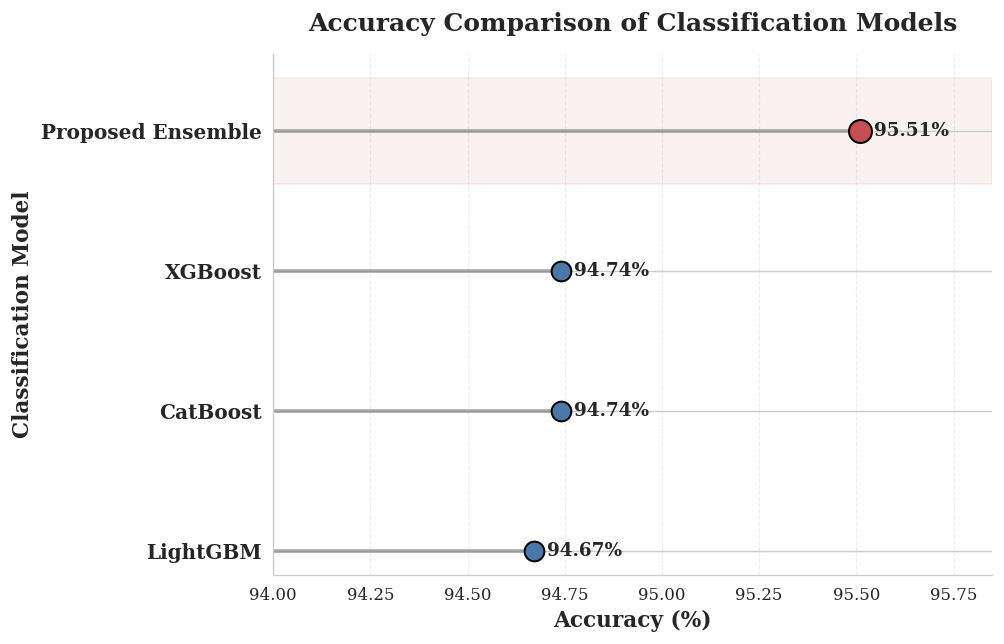

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Q1-JOURNAL LEVEL ACCURACY COMPARISON
# ============================================================

# Data — use the ACTUAL final results
models = [
    "LightGBM",
    "CatBoost",
    "XGBoost",
    "Proposed Ensemble"
]

accuracy = np.array([
    94.67,
    94.74,
    94.74,
    95.51
])

# ------------------------------------------------------------
# Use an available serif font
# Avoids: "Times New Roman not found"
# ------------------------------------------------------------
plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["font.size"] = 11

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.5))

y = np.arange(len(models))

# ------------------------------------------------------------
# Horizontal reference lines
# ------------------------------------------------------------
for yi in y:
    ax.axhline(
        yi,
        color="lightgray",
        linewidth=0.8,
        alpha=0.55,
        zorder=0
    )

# ------------------------------------------------------------
# Connecting lines
# ------------------------------------------------------------
for yi, value in zip(y, accuracy):

    ax.plot(
        [94.0, value],
        [yi, yi],
        linewidth=2.2,
        color="gray",
        alpha=0.65,
        zorder=1
    )

# ------------------------------------------------------------
# Points
# ------------------------------------------------------------
for i, (yi, value) in enumerate(zip(y, accuracy)):

    if models[i] == "Proposed Ensemble":
        point_color = "#C44E52"
        point_size = 190
    else:
        point_color = "#4C78A8"
        point_size = 140

    ax.scatter(
        value,
        yi,
        s=point_size,
        color=point_color,
        edgecolor="black",
        linewidth=1.2,
        zorder=3
    )

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------
for yi, value in zip(y, accuracy):

    ax.text(
        value + 0.035,
        yi,
        f"{value:.2f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Highlight proposed ensemble
# ------------------------------------------------------------
proposed_index = models.index("Proposed Ensemble")

ax.axhspan(
    proposed_index - 0.38,
    proposed_index + 0.38,
    color="#C44E52",
    alpha=0.08,
    zorder=0
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------
ax.set_yticks(y)
ax.set_yticklabels(
    models,
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel(
    "Accuracy (%)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Classification Model",
    fontsize=13,
    fontweight="bold"
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------
ax.set_title(
    "Accuracy Comparison of Classification Models",
    fontsize=15,
    fontweight="bold",
    pad=14
)

# ------------------------------------------------------------
# Axis limits
# ------------------------------------------------------------
ax.set_xlim(94.0, 95.85)

# ------------------------------------------------------------
# X-axis ticks
# ------------------------------------------------------------
ax.set_xticks(
    np.arange(94.0, 96.0, 0.25)
)

ax.tick_params(
    axis="x",
    labelsize=10
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

# ------------------------------------------------------------
# Remove unnecessary borders
# ------------------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep left/bottom subtle
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------
plt.tight_layout()

# ------------------------------------------------------------
# Save — high resolution
# ------------------------------------------------------------
plt.savefig(
    "Figure_Accuracy_Comparison_Q1.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_Accuracy_Comparison_Q1.pdf",
    bbox_inches="tight"
)

plt.show()

In [46]:
# ============================================================
# ENSEMBLE ABLATION STUDY — E1 TO E4
# USES THE SAME FINAL MODELS AND TEST SET AS MAIN EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 80)
print("ENSEMBLE ABLATION STUDY")
print("=" * 80)


# ============================================================
# STEP 1 — GET THE SAME TEST PROBABILITIES USED IN MAIN MODEL
# ============================================================

xgb_prob = best_xgb.predict_proba(X_test_scaled)[:, 1]
lgb_prob = best_lgb.predict_proba(X_test_scaled)[:, 1]
cat_prob = best_cat.predict_proba(X_test_scaled)[:, 1]

y_true = np.asarray(y_test)


# ============================================================
# STEP 2 — GET THE ACTUAL VALIDATION-OPTIMIZED WEIGHTS
# ============================================================

wx, wl, wc = best_weights

print("\nActual selected ensemble weights:")
print(f"XGBoost  : {wx:.4f}")
print(f"LightGBM : {wl:.4f}")
print(f"CatBoost : {wc:.4f}")


# ============================================================
# STEP 3 — DEFINE ABLATION CONFIGURATIONS
# ============================================================

# E1 — XGBoost only
E1_prob = xgb_prob


# E2 — XGBoost + LightGBM
E2_prob = (
    0.5 * xgb_prob +
    0.5 * lgb_prob
)


# E3 — XGBoost + LightGBM + CatBoost
# Equal contribution
E3_prob = (
    (1/3) * xgb_prob +
    (1/3) * lgb_prob +
    (1/3) * cat_prob
)


# E4 — EXACT PROPOSED ENSEMBLE
# Uses the SAME weights selected by your
# validation-based optimization.
E4_prob = (
    wx * xgb_prob +
    wl * lgb_prob +
    wc * cat_prob
)


# ============================================================
# STEP 4 — EVALUATION FUNCTION
# ============================================================

def evaluate_configuration(name, probability):

    prediction = (
        probability >= 0.5
    ).astype(int)

    return {
        "Configuration": name,
        "Accuracy": accuracy_score(
            y_true,
            prediction
        ),
        "Precision": precision_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            probability
        )
    }


# ============================================================
# STEP 5 — RUN ABLATION
# ============================================================

ablation_results = pd.DataFrame([

    evaluate_configuration(
        "E1: XGBoost",
        E1_prob
    ),

    evaluate_configuration(
        "E2: XGBoost + LightGBM",
        E2_prob
    ),

    evaluate_configuration(
        "E3: XGBoost + LightGBM + CatBoost",
        E3_prob
    ),

    evaluate_configuration(
        "E4: Proposed Weighted Ensemble",
        E4_prob
    )

])


# ============================================================
# STEP 6 — DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("FINAL ENSEMBLE ABLATION RESULTS")
print("=" * 80)

display(
    ablation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# ============================================================
# STEP 7 — SAVE TABLE
# ============================================================

ablation_results.to_csv(
    "Table_Ensemble_Ablation_E1_E4.csv",
    index=False
)

print("\n✓ Saved: Table_Ensemble_Ablation_E1_E4.csv")

ENSEMBLE ABLATION STUDY

Actual selected ensemble weights:
XGBoost  : 0.1000
LightGBM : 0.8000
CatBoost : 0.1000


FINAL ENSEMBLE ABLATION RESULTS


,Configuration,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,E1: XGBoost,0.9516,0.9466,0.8708,0.9071,0.9782
1,E2: XGBoost + LightGBM,0.9565,0.9552,0.8811,0.9167,0.9795
2,E3: XGBoost + LightGBM + CatBoost,0.9565,0.9552,0.8811,0.9167,0.9811
3,E4: Proposed Weighted Ensemble,0.9579,0.9580,0.8837,0.9194,0.9815



✓ Saved: Table_Ensemble_Ablation_E1_E4.csv


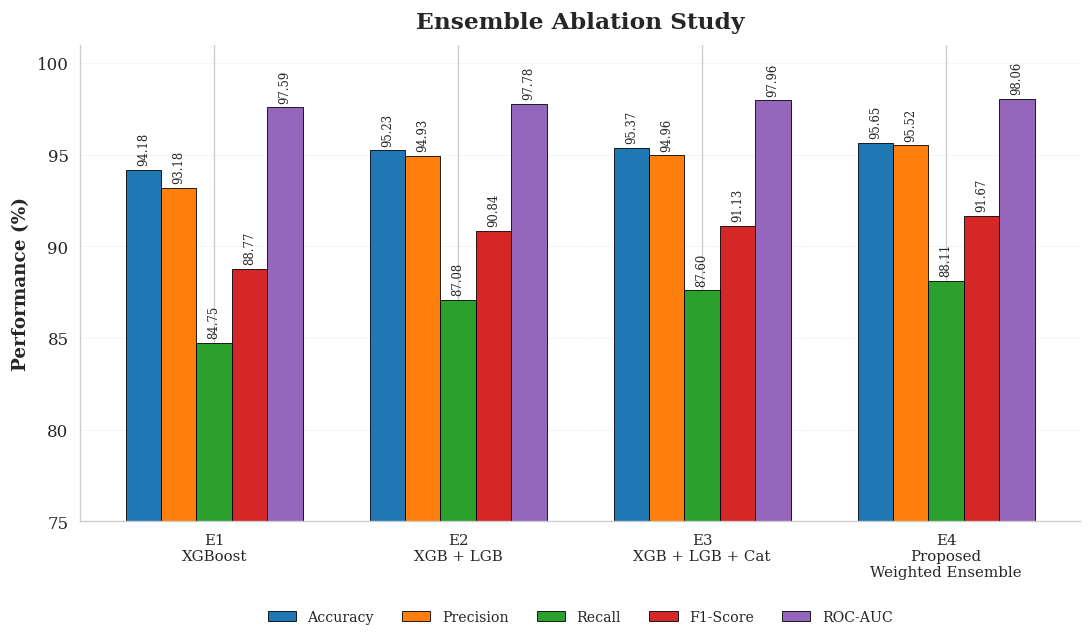

ENSEMBLE ABLATION FIGURE GENERATED
PNG : /content/Ensemble_Ablation_Study_Q1.png
PDF : /content/Ensemble_Ablation_Study_Q1.pdf
TIFF: /content/Ensemble_Ablation_Study_Q1.tiff


In [47]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# ENSEMBLE ABLATION STUDY — JOURNAL-LEVEL FIGURE
# ============================================================

configs = [
    "E1\nXGBoost",
    "E2\nXGB + LGB",
    "E3\nXGB + LGB + Cat",
    "E4\nProposed\nWeighted Ensemble"
]

# Results from the ablation experiment
data = {
    "Accuracy":  [94.18, 95.23, 95.37, 95.65],
    "Precision": [93.18, 94.93, 94.96, 95.52],
    "Recall":    [84.75, 87.08, 87.60, 88.11],
    "F1-Score":  [88.77, 90.84, 91.13, 91.67],
    "ROC-AUC":   [97.59, 97.78, 97.96, 98.06]
}

# ============================================================
# FONT
# DejaVu Serif is available by default in Colab/Linux
# and avoids Times New Roman "findfont" warnings.
# ============================================================

plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["font.size"] = 10

# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(9.2, 5.5))

x = np.arange(len(configs))
width = 0.145

# ============================================================
# BAR PLOT
# ============================================================

for i, (metric, values) in enumerate(data.items()):

    bars = ax.bar(
        x + (i - 2) * width,
        values,
        width=width,
        label=metric,
        edgecolor="black",
        linewidth=0.5
    )

    # Value labels
    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.25,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90
        )

# ============================================================
# TITLES AND LABELS
# ============================================================

ax.set_title(
    "Ensemble Ablation Study",
    fontsize=14,
    fontweight="bold",
    pad=10
)



ax.set_ylabel(
    "Performance (%)",
    fontsize=11,
    fontweight="bold"
)

# ============================================================
# X-AXIS
# ============================================================

ax.set_xticks(x)
ax.set_xticklabels(
    configs,
    fontsize=9
)

# ============================================================
# Y-AXIS
# ============================================================

ax.set_ylim(75, 101)

ax.set_yticks(
    np.arange(75, 101, 5)
)

# ============================================================
# GRID
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.3
)

ax.set_axisbelow(True)

# ============================================================
# REMOVE UNNECESSARY SPINES
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# LEGEND
# ============================================================

ax.legend(
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    frameon=False,
    fontsize=8.5
)

# ============================================================
# FINAL LAYOUT
# ============================================================

fig.tight_layout()

# ============================================================
# SAVE HIGH-QUALITY FILES
# ============================================================

png_path = "/content/Ensemble_Ablation_Study_Q1.png"
pdf_path = "/content/Ensemble_Ablation_Study_Q1.pdf"
tiff_path = "/content/Ensemble_Ablation_Study_Q1.tiff"

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("ENSEMBLE ABLATION FIGURE GENERATED")
print("=" * 70)
print("PNG :", png_path)
print("PDF :", pdf_path)
print("TIFF:", tiff_path)

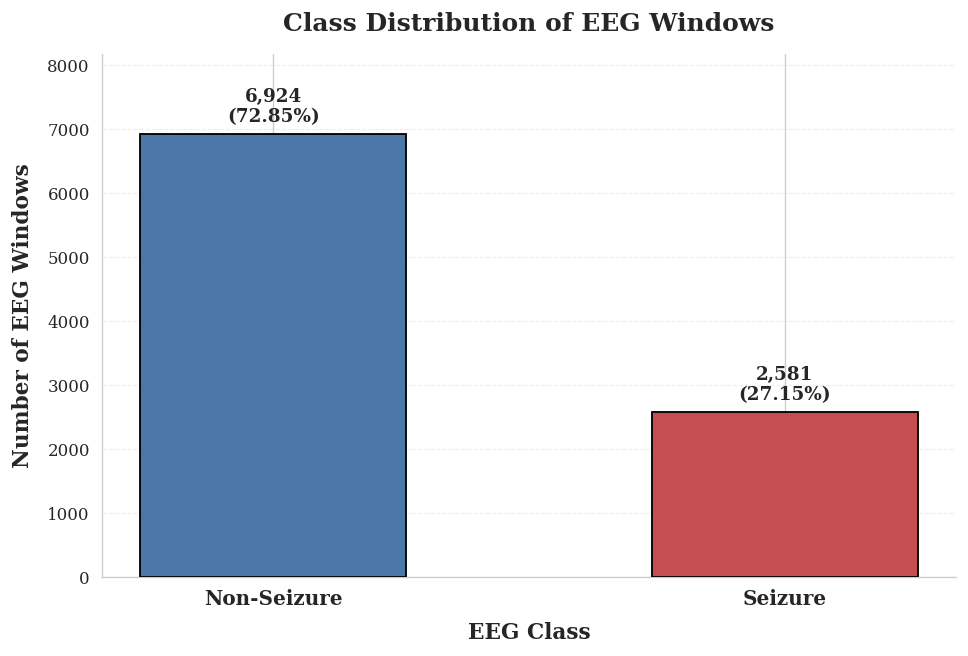

✓ Figure_1_Class_Distribution.png saved
✓ Figure_1_Class_Distribution.pdf saved


In [48]:
# ============================================================
# FIGURE 1 : CLASS DISTRIBUTION
# Q1-JOURNAL QUALITY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Dataset values from the verified EEG dataset
# ------------------------------------------------------------

classes = [
    "Non-Seizure",
    "Seizure"
]

counts = np.array([
    6924,
    2581
])

total = counts.sum()
percentages = (counts / total) * 100

# ------------------------------------------------------------
# Publication font
# DejaVu Serif is available and avoids Times New Roman error
# ------------------------------------------------------------

plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["font.size"] = 11

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 5.6))

x = np.arange(len(classes))

# ------------------------------------------------------------
# Bars
# ------------------------------------------------------------

bars = ax.bar(
    x,
    counts,
    width=0.52,
    color=["#4C78A8", "#C44E52"],
    edgecolor="black",
    linewidth=1.1,
    zorder=3
)

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------

for bar, count, pct in zip(
    bars,
    counts,
    percentages
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "EEG Class",
    fontsize=13,
    fontweight="bold",
    labelpad=8
)

ax.set_ylabel(
    "Number of EEG Windows",
    fontsize=13,
    fontweight="bold",
    labelpad=8
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Class Distribution of EEG Windows",
    fontsize=15,
    fontweight="bold",
    pad=14
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xticks(x)

ax.set_xticklabels(
    classes,
    fontsize=12,
    fontweight="bold"
)

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_ylim(
    0,
    max(counts) * 1.18
)

ax.tick_params(
    axis="y",
    labelsize=10
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.30,
    zorder=0
)

# ------------------------------------------------------------
# Clean journal-style axes
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save high-resolution figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_1_Class_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_1_Class_Distribution.pdf",
    bbox_inches="tight"
)

plt.show()

print("✓ Figure_1_Class_Distribution.png saved")
print("✓ Figure_1_Class_Distribution.pdf saved")

18-CHANNEL EEG VISUALIZATION
Raw EEG shape : (9505, 18, 2048)

Reconstructing raw EEG labels...
y_train shape : (6653,)
y_temp shape  : (2852,)
raw_labels shape : (9505,)
✓ EEG windows and labels match

Raw label distribution:
Class 0: 6924
Class 1: 2581

Non-Seizure windows : 6924
Seizure windows     : 2581

Selected representative windows:
Non-Seizure index : 4744
Seizure index     : 4779

Non-Seizure EEG shape : (18, 2048)
Seizure EEG shape     : (18, 2048)


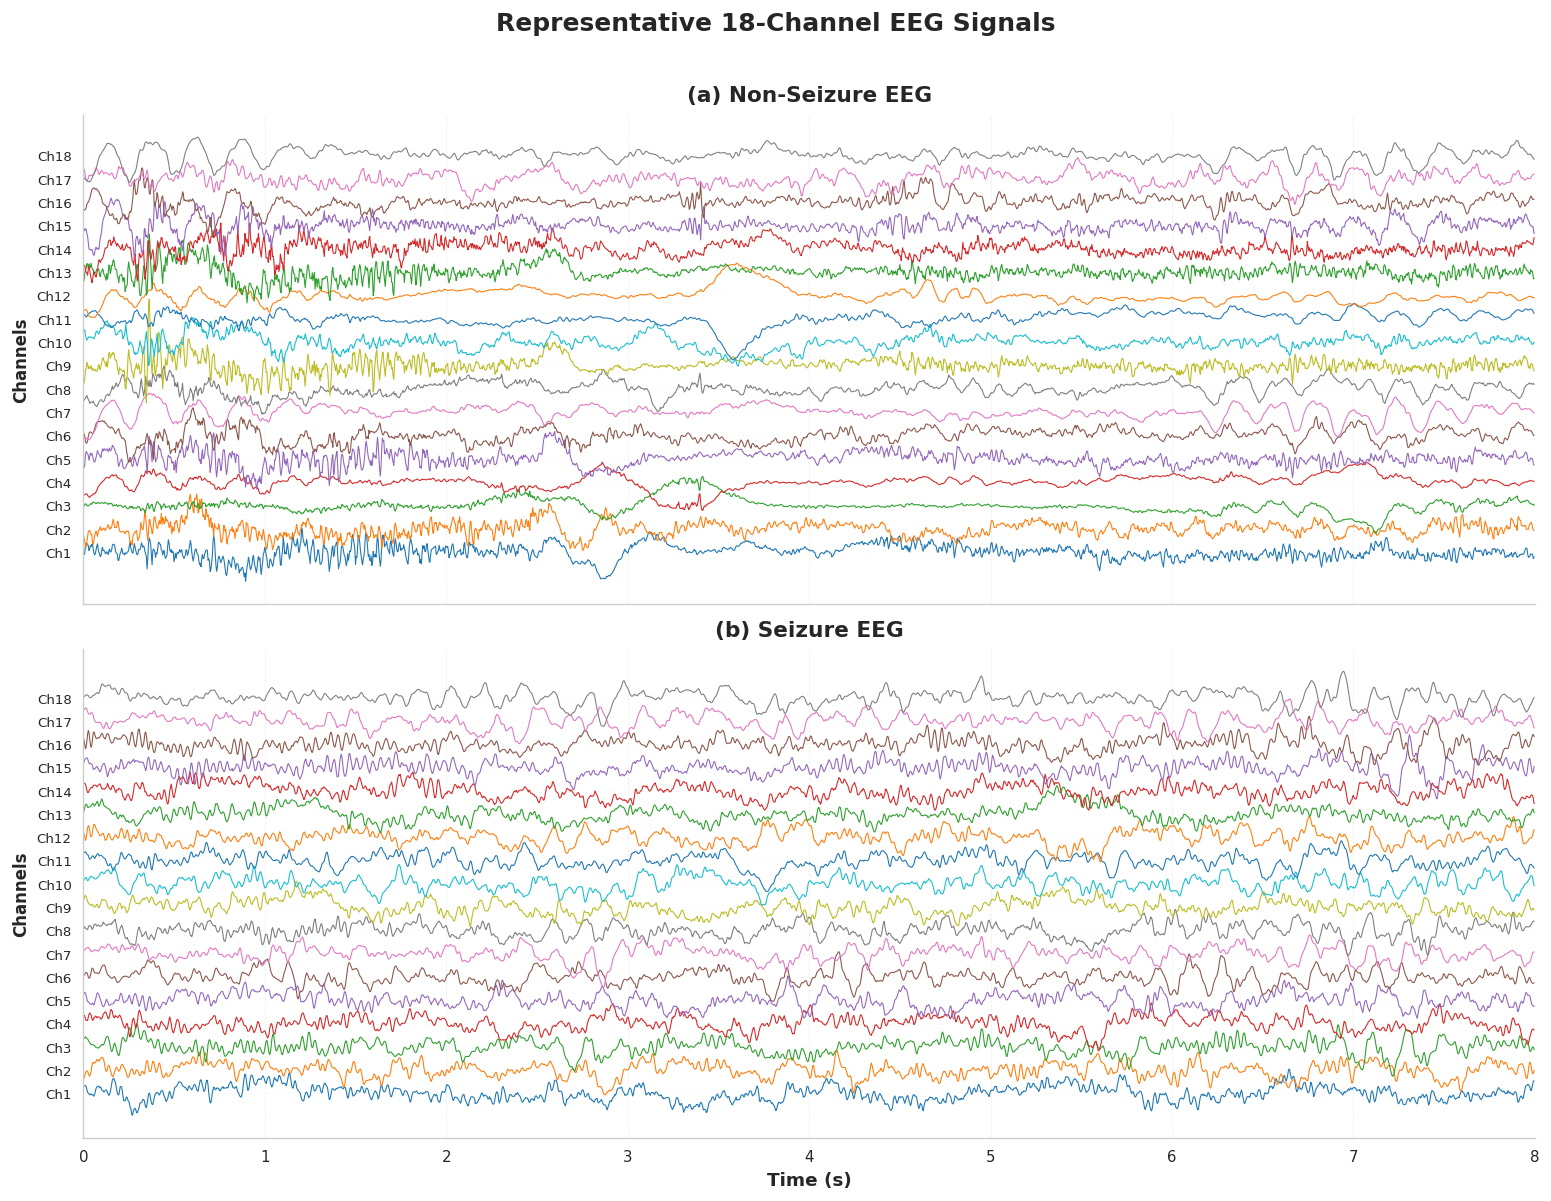


FIGURE SAVED SUCCESSFULLY
✓ 18 channels shown
✓ Non-Seizure and Seizure shown
✓ Sampling frequency : 256 Hz
✓ Window duration     : 8.0 seconds
✓ EEG shape           : (9505, 18, 2048)
✓ Labels reconstructed: (9505,)
✓ PNG resolution      : 600 DPI
✓ PDF vector output   : available


In [49]:
# ============================================================
# Q1 JOURNAL-LEVEL FIGURE
# 18-CHANNEL EEG: NON-SEIZURE vs SEIZURE
# CORRECTED VERSION FOR CURRENT PIPELINE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ------------------------------------------------------------
# Publication-safe font
# ------------------------------------------------------------
rcParams["font.family"] = "DejaVu Sans"
rcParams["font.size"] = 9

# ------------------------------------------------------------
# EEG parameters
# ------------------------------------------------------------
FS = 256
N_CHANNELS = 18
WINDOW_SAMPLES = 2048
WINDOW_SECONDS = WINDOW_SAMPLES / FS

# ============================================================
# 1. CHECK RAW EEG DATA
# ============================================================

print("=" * 70)
print("18-CHANNEL EEG VISUALIZATION")
print("=" * 70)

print("Raw EEG shape :", signals.shape)

assert signals.ndim == 3, \
    f"Expected 3-D EEG data, got {signals.ndim}-D"

assert signals.shape[1] == N_CHANNELS, \
    f"Expected {N_CHANNELS} channels, got {signals.shape[1]}"

assert signals.shape[2] == WINDOW_SAMPLES, \
    f"Expected {WINDOW_SAMPLES} samples, got {signals.shape[2]}"

# ============================================================
# 2. RECONSTRUCT LABELS FOR ALL 9505 RAW WINDOWS
# ============================================================

print("\nReconstructing raw EEG labels...")

print("y_train shape :", y_train.shape)
print("y_temp shape  :", y_temp.shape)

# 6653 + 2852 = 9505
raw_labels = np.concatenate([
    np.asarray(y_train).reshape(-1),
    np.asarray(y_temp).reshape(-1)
])

print("raw_labels shape :", raw_labels.shape)

# ------------------------------------------------------------
# Verify exact match
# ------------------------------------------------------------

if len(raw_labels) != len(signals):

    raise ValueError(
        f"Label/data mismatch:\n"
        f"signals = {len(signals)}\n"
        f"raw_labels = {len(raw_labels)}"
    )

print("✓ EEG windows and labels match")

# ============================================================
# 3. CHECK LABEL VALUES
# ============================================================

unique_labels, label_counts = np.unique(
    raw_labels,
    return_counts=True
)

print("\nRaw label distribution:")
for label, count in zip(unique_labels, label_counts):
    print(f"Class {label}: {count}")

# ============================================================
# 4. FIND NON-SEIZURE AND SEIZURE INDICES
# ============================================================

# Assumption from your classification pipeline:
# 0 = Non-Seizure
# 1 = Seizure

non_seizure_indices = np.where(
    raw_labels == 0
)[0]

seizure_indices = np.where(
    raw_labels == 1
)[0]

print("\nNon-Seizure windows :", len(non_seizure_indices))
print("Seizure windows     :", len(seizure_indices))

# ============================================================
# 5. SAFETY CHECK
# ============================================================

if len(non_seizure_indices) == 0:
    raise ValueError(
        "No Non-Seizure windows found. "
        "Check class encoding."
    )

if len(seizure_indices) == 0:
    raise ValueError(
        "No Seizure windows found. "
        "Check class encoding."
    )

# ============================================================
# 6. SELECT REPRESENTATIVE WINDOWS
# ============================================================

# Use median-position samples rather than first sample.
non_idx = non_seizure_indices[
    len(non_seizure_indices) // 2
]

sei_idx = seizure_indices[
    len(seizure_indices) // 2
]

non_eeg = signals[non_idx]
sei_eeg = signals[sei_idx]

print("\nSelected representative windows:")
print("Non-Seizure index :", non_idx)
print("Seizure index     :", sei_idx)

print("\nNon-Seizure EEG shape :", non_eeg.shape)
print("Seizure EEG shape     :", sei_eeg.shape)

# ============================================================
# 7. CHANNEL LABELS
# ============================================================

channel_names = [
    "Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6",
    "Ch7", "Ch8", "Ch9", "Ch10", "Ch11", "Ch12",
    "Ch13", "Ch14", "Ch15", "Ch16", "Ch17", "Ch18"
]

# ============================================================
# 8. TIME AXIS
# ============================================================

time = np.arange(WINDOW_SAMPLES) / FS

# ============================================================
# 9. NORMALIZATION FOR VISUALIZATION ONLY
# ============================================================

def normalize_eeg(eeg):

    eeg = np.asarray(eeg, dtype=np.float64)

    normalized = np.zeros_like(eeg)

    for ch in range(eeg.shape[0]):

        signal = eeg[ch]

        mean = np.mean(signal)
        std = np.std(signal)

        if std > 0:
            normalized[ch] = (
                signal - mean
            ) / std

        else:
            normalized[ch] = signal - mean

    return normalized


non_plot = normalize_eeg(non_eeg)
sei_plot = normalize_eeg(sei_eeg)

# ============================================================
# 10. PLOT
# ============================================================

spacing = 3.2

fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 10),
    sharex=True
)

# ============================================================
# (a) NON-SEIZURE
# ============================================================

ax = axes[0]

for ch in range(N_CHANNELS):

    ax.plot(
        time,
        non_plot[ch] + ch * spacing,
        linewidth=0.65
    )

ax.set_yticks(
    np.arange(N_CHANNELS) * spacing
)

ax.set_yticklabels(
    channel_names,
    fontsize=8
)

ax.set_ylabel(
    "Channels",
    fontsize=10,
    fontweight="bold"
)

ax.set_title(
    "(a) Non-Seizure EEG",
    fontsize=13,
    fontweight="bold",
    pad=8
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.45,
    alpha=0.35
)

ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.35,
    alpha=0.20
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# (b) SEIZURE
# ============================================================

ax = axes[1]

for ch in range(N_CHANNELS):

    ax.plot(
        time,
        sei_plot[ch] + ch * spacing,
        linewidth=0.65
    )

ax.set_yticks(
    np.arange(N_CHANNELS) * spacing
)

ax.set_yticklabels(
    channel_names,
    fontsize=8
)

ax.set_ylabel(
    "Channels",
    fontsize=10,
    fontweight="bold"
)

ax.set_title(
    "(b) Seizure EEG",
    fontsize=13,
    fontweight="bold",
    pad=8
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.45,
    alpha=0.35
)

ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.35,
    alpha=0.20
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# 11. X-AXIS
# ============================================================

axes[1].set_xlabel(
    "Time (s)",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_xlim(
    0,
    WINDOW_SECONDS
)

axes[1].set_xticks(
    np.arange(
        0,
        WINDOW_SECONDS + 1,
        1
    )
)

# ============================================================
# 12. OVERALL TITLE
# ============================================================

fig.suptitle(
    "Representative 18-Channel EEG Signals",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

# ============================================================
# 13. LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.98]
)

# ============================================================
# 14. SAVE JOURNAL-QUALITY FIGURES
# ============================================================

plt.savefig(
    "Figure_18Channel_EEG_Seizure_NonSeizure.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_18Channel_EEG_Seizure_NonSeizure.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. FINAL INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("FIGURE SAVED SUCCESSFULLY")
print("=" * 70)

print("✓ 18 channels shown")
print("✓ Non-Seizure and Seizure shown")
print("✓ Sampling frequency :", FS, "Hz")
print("✓ Window duration     :", WINDOW_SECONDS, "seconds")
print("✓ EEG shape           :", signals.shape)
print("✓ Labels reconstructed:", raw_labels.shape)
print("✓ PNG resolution      : 600 DPI")
print("✓ PDF vector output   : available")

PROPOSED ENSEMBLE - CONFUSION MATRIX

Confusion Matrix:
[[1024   15]
 [  45  342]]

Accuracy: 0.9579 (95.79%)

TN : 1024
FP : 15
FN : 45
TP : 342


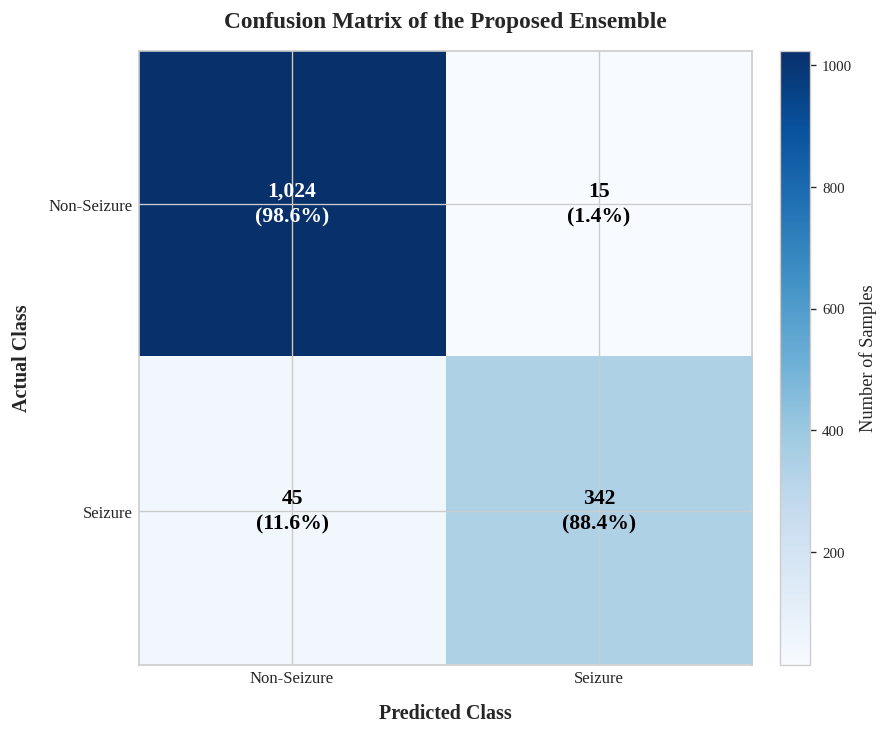


✓ Saved:
  Fig_Confusion_Matrix_Proposed_Ensemble_Q1.png
  Fig_Confusion_Matrix_Proposed_Ensemble_Q1.pdf


In [50]:
# ================================================================
# JOURNAL-QUALITY CONFUSION MATRIX
# Proposed Ensemble – EEG Seizure Classification
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score
from matplotlib import font_manager

# ------------------------------------------------
# 1. Use the ACTUAL test labels and predictions
# ------------------------------------------------
# Your existing variables:
# y_true          -> actual test labels
# ensemble_pred   -> Proposed Ensemble predictions

y_actual = np.asarray(y_true).astype(int)
y_prediction = np.asarray(ensemble_pred).astype(int)

# ------------------------------------------------
# 2. Calculate confusion matrix
# ------------------------------------------------
cm = confusion_matrix(
    y_actual,
    y_prediction,
    labels=[0, 1]
)

accuracy = accuracy_score(y_actual, y_prediction)

# ------------------------------------------------
# 3. Row-wise percentages
# ------------------------------------------------
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

print("=" * 70)
print("PROPOSED ENSEMBLE - CONFUSION MATRIX")
print("=" * 70)

print("\nConfusion Matrix:")
print(cm)

print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

print("\nTN :", cm[0, 0])
print("FP :", cm[0, 1])
print("FN :", cm[1, 0])
print("TP :", cm[1, 1])

# ------------------------------------------------
# 4. Font – avoids Times New Roman warning
# ------------------------------------------------
available_fonts = {
    f.name for f in font_manager.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    FONT = "Times New Roman"
elif "Liberation Serif" in available_fonts:
    FONT = "Liberation Serif"
else:
    FONT = "DejaVu Serif"

plt.rcParams["font.family"] = FONT

# ------------------------------------------------
# 5. Create figure
# ------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 6.2))

# Use imshow instead of seaborn
im = ax.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

# ------------------------------------------------
# 6. Colorbar
# ------------------------------------------------
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Number of Samples",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=9
)

# ------------------------------------------------
# 7. Axis labels
# ------------------------------------------------
class_names = [
    "Non-Seizure",
    "Seizure"
]

ax.set(
    xticks=np.arange(2),
    yticks=np.arange(2),
    xticklabels=class_names,
    yticklabels=class_names
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Actual Class",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

# ------------------------------------------------
# 8. Tick formatting
# ------------------------------------------------
ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    length=0
)

# ------------------------------------------------
# 9. Annotate count + percentage
# ------------------------------------------------
threshold = cm.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        count = cm[i, j]
        percentage = cm_percent[i, j]

        # White text for darker cells
        text_color = "white" if count > threshold else "black"

        ax.text(
            j,
            i,
            f"{count:,}\n({percentage:.1f}%)",
            ha="center",
            va="center",
            color=text_color,
            fontsize=13,
            fontweight="bold",
            linespacing=1.4
        )

# ------------------------------------------------
# 10. Clean journal-style borders
# ------------------------------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.0)

# ------------------------------------------------
# 11. Title
# ------------------------------------------------
ax.set_title(
    "Confusion Matrix of the Proposed Ensemble",
    fontsize=14,
    fontweight="bold",
    pad=14
)

# ------------------------------------------------
# 12. Layout
# ------------------------------------------------
plt.tight_layout()

# ------------------------------------------------
# 13. Save high-resolution figure
# ------------------------------------------------
plt.savefig(
    "Fig_Confusion_Matrix_Proposed_Ensemble_Q1.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Fig_Confusion_Matrix_Proposed_Ensemble_Q1.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\n✓ Saved:")
print("  Fig_Confusion_Matrix_Proposed_Ensemble_Q1.png")
print("  Fig_Confusion_Matrix_Proposed_Ensemble_Q1.pdf")

Using ensemble probability: ensemble_prob


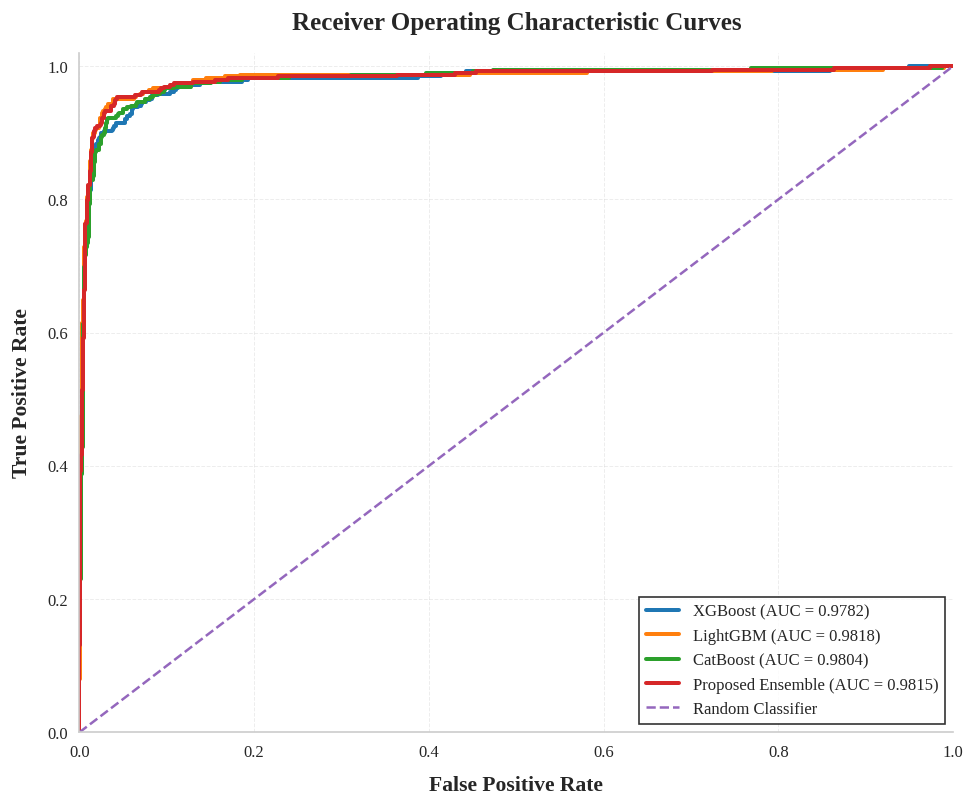

ROC CURVE RESULTS
XGBoost                   AUC = 0.9782
LightGBM                  AUC = 0.9818
CatBoost                  AUC = 0.9804
Proposed Ensemble         AUC = 0.9815

✓ Saved:
  Fig_ROC_Curves_EEG_Q1.png
  Fig_ROC_Curves_EEG_Q1.pdf


In [51]:
# ================================================================
# JOURNAL-QUALITY ROC CURVES
# EEG SEIZURE CLASSIFICATION
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from matplotlib import font_manager

# ================================================================
# 1. Actual test labels
# ================================================================

y_actual = np.asarray(y_true).astype(int)

# ================================================================
# 2. Font without Times New Roman warning
# ================================================================

available_fonts = {
    f.name for f in font_manager.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    FONT = "Times New Roman"
elif "Liberation Serif" in available_fonts:
    FONT = "Liberation Serif"
else:
    FONT = "DejaVu Serif"

plt.rcParams["font.family"] = FONT

# ================================================================
# 3. Collect model probabilities
# ================================================================

roc_data = {}

# XGBoost
if "xgb_test" in globals():
    roc_data["XGBoost"] = np.asarray(xgb_test)

# LightGBM
if "lgb_test" in globals():
    roc_data["LightGBM"] = np.asarray(lgb_test)

# CatBoost
if "cat_test" in globals():
    roc_data["CatBoost"] = np.asarray(cat_test)

# ================================================================
# 4. Proposed Ensemble probability
# ================================================================
# IMPORTANT:
# Use the probability generated by your FINAL proposed ensemble.
#
# If your ensemble probability variable already exists, this block
# automatically detects common variable names.

ensemble_probability = None

possible_ensemble_names = [
    "ensemble_prob",
    "ensemble_probability",
    "weighted_prob",
    "weighted_ensemble_prob",
    "final_prob",
    "proposed_prob",
    "ensemble_test_prob"
]

for name in possible_ensemble_names:
    if name in globals():
        ensemble_probability = np.asarray(globals()[name])
        print(f"Using ensemble probability: {name}")
        break

if ensemble_probability is not None:
    roc_data["Proposed Ensemble"] = ensemble_probability

# ================================================================
# 5. Safety check
# ================================================================

if len(roc_data) == 0:
    raise ValueError(
        "No model probability arrays were found. "
        "Check xgb_test, lgb_test, cat_test and ensemble probability variables."
    )

for name, prob in roc_data.items():

    if len(prob) != len(y_actual):
        raise ValueError(
            f"{name}: probability length {len(prob)} "
            f"does not match y_true length {len(y_actual)}"
        )

# ================================================================
# 6. Create ROC figure
# ================================================================

fig, ax = plt.subplots(figsize=(8.2, 6.8))

# ================================================================
# 7. Plot each ROC curve
# ================================================================

for model_name, probabilities in roc_data.items():

    fpr, tpr, _ = roc_curve(
        y_actual,
        probabilities
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2.4,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

# ================================================================
# 8. Random classifier reference
# ================================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

# ================================================================
# 9. Axis labels
# ================================================================

ax.set_xlabel(
    "False Positive Rate",
    fontsize=13,
    fontweight="bold",
    labelpad=9
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=13,
    fontweight="bold",
    labelpad=9
)

# ================================================================
# 10. Title
# ================================================================

ax.set_title(
    "Receiver Operating Characteristic Curves",
    fontsize=15,
    fontweight="bold",
    pad=14
)

# ================================================================
# 11. Axis limits
# ================================================================

ax.set_xlim(
    0.0,
    1.0
)

ax.set_ylim(
    0.0,
    1.02
)

# ================================================================
# 12. Ticks
# ================================================================

ax.tick_params(
    axis="both",
    labelsize=10
)

# ================================================================
# 13. Grid
# ================================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

# ================================================================
# 14. Legend
# ================================================================

ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
    fancybox=False,
    edgecolor="black"
)

# ================================================================
# 15. Clean borders
# ================================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

# ================================================================
# 16. Layout
# ================================================================

plt.tight_layout()

# ================================================================
# 17. Save Q1-quality files
# ================================================================

plt.savefig(
    "Fig_ROC_Curves_EEG_Q1.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Fig_ROC_Curves_EEG_Q1.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("=" * 70)
print("ROC CURVE RESULTS")
print("=" * 70)

for model_name, probabilities in roc_data.items():

    fpr, tpr, _ = roc_curve(
        y_actual,
        probabilities
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    print(
        f"{model_name:<25} AUC = {roc_auc:.4f}"
    )

print("\n✓ Saved:")
print("  Fig_ROC_Curves_EEG_Q1.png")
print("  Fig_ROC_Curves_EEG_Q1.pdf")

Using ensemble probability: ensemble_prob


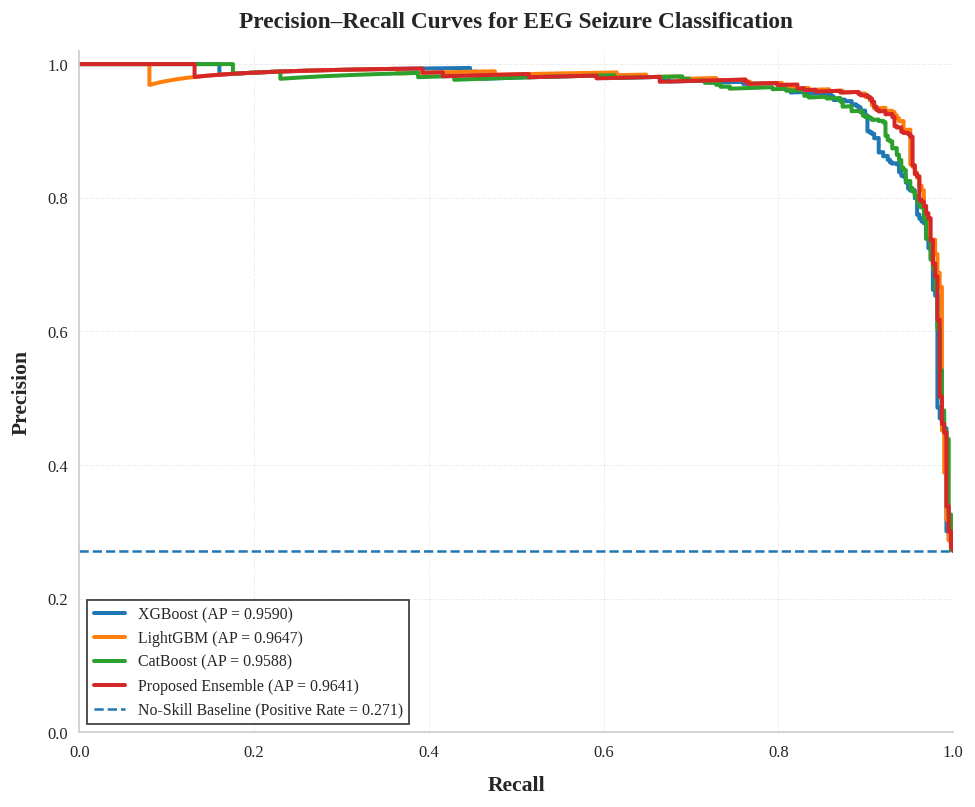

PRECISION–RECALL RESULTS
Positive-class prevalence: 0.2714
XGBoost                   Average Precision = 0.9590
LightGBM                  Average Precision = 0.9647
CatBoost                  Average Precision = 0.9588
Proposed Ensemble         Average Precision = 0.9641

✓ Saved:
  Fig_Precision_Recall_Curves_EEG_Q1.png
  Fig_Precision_Recall_Curves_EEG_Q1.pdf


In [52]:
# ================================================================
# JOURNAL-QUALITY PRECISION–RECALL CURVES
# EEG SEIZURE CLASSIFICATION
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
from matplotlib import font_manager

# ================================================================
# 1. Actual test labels
# ================================================================

y_actual = np.asarray(y_true).astype(int)

# ================================================================
# 2. Font - avoids Times New Roman warning
# ================================================================

available_fonts = {
    f.name for f in font_manager.fontManager.ttflist
}

if "Times New Roman" in available_fonts:
    FONT = "Times New Roman"
elif "Liberation Serif" in available_fonts:
    FONT = "Liberation Serif"
else:
    FONT = "DejaVu Serif"

plt.rcParams["font.family"] = FONT

# ================================================================
# 3. Collect model probabilities
# ================================================================

pr_data = {}

# XGBoost
if "xgb_test" in globals():
    pr_data["XGBoost"] = np.asarray(xgb_test)

# LightGBM
if "lgb_test" in globals():
    pr_data["LightGBM"] = np.asarray(lgb_test)

# CatBoost
if "cat_test" in globals():
    pr_data["CatBoost"] = np.asarray(cat_test)

# ================================================================
# 4. Find FINAL proposed ensemble probability
# ================================================================

ensemble_probability = None

possible_ensemble_names = [
    "ensemble_prob",
    "ensemble_probability",
    "weighted_prob",
    "weighted_ensemble_prob",
    "final_prob",
    "proposed_prob",
    "ensemble_test_prob"
]

for name in possible_ensemble_names:

    if name in globals():

        ensemble_probability = np.asarray(
            globals()[name]
        )

        print(
            f"Using ensemble probability: {name}"
        )

        break

# Add proposed ensemble only if actual probability exists
if ensemble_probability is not None:

    pr_data["Proposed Ensemble"] = (
        ensemble_probability
    )

# ================================================================
# 5. Safety checks
# ================================================================

if len(pr_data) == 0:

    raise ValueError(
        "No probability arrays found. "
        "Check xgb_test, lgb_test, cat_test and "
        "your final ensemble probability variable."
    )

for model_name, probabilities in pr_data.items():

    if len(probabilities) != len(y_actual):

        raise ValueError(
            f"{model_name}: probability length "
            f"{len(probabilities)} does not match "
            f"y_true length {len(y_actual)}"
        )

# ================================================================
# 6. Create figure
# ================================================================

fig, ax = plt.subplots(
    figsize=(8.2, 6.8)
)

# ================================================================
# 7. Plot Precision–Recall curves
# ================================================================

for model_name, probabilities in pr_data.items():

    precision, recall, _ = precision_recall_curve(
        y_actual,
        probabilities
    )

    average_precision = average_precision_score(
        y_actual,
        probabilities
    )

    ax.plot(
        recall,
        precision,
        linewidth=2.4,
        label=(
            f"{model_name} "
            f"(AP = {average_precision:.4f})"
        )
    )

# ================================================================
# 8. No-skill baseline
# ================================================================

positive_rate = np.mean(y_actual)

ax.axhline(
    positive_rate,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"No-Skill Baseline "
        f"(Positive Rate = {positive_rate:.3f})"
    )
)

# ================================================================
# 9. Axis labels
# ================================================================

ax.set_xlabel(
    "Recall",
    fontsize=13,
    fontweight="bold",
    labelpad=9
)

ax.set_ylabel(
    "Precision",
    fontsize=13,
    fontweight="bold",
    labelpad=9
)

# ================================================================
# 10. Title
# ================================================================

ax.set_title(
    "Precision–Recall Curves for EEG Seizure Classification",
    fontsize=14,
    fontweight="bold",
    pad=14
)

# ================================================================
# 11. Axis limits
# ================================================================

ax.set_xlim(
    0.0,
    1.0
)

ax.set_ylim(
    0.0,
    1.02
)

# ================================================================
# 12. Ticks
# ================================================================

ax.tick_params(
    axis="both",
    labelsize=10
)

# ================================================================
# 13. Grid
# ================================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

# ================================================================
# 14. Legend
# ================================================================

ax.legend(
    loc="lower left",
    fontsize=9.5,
    frameon=True,
    fancybox=False,
    edgecolor="black"
)

# ================================================================
# 15. Clean borders
# ================================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

# ================================================================
# 16. Layout
# ================================================================

plt.tight_layout()

# ================================================================
# 17. Save high-resolution files
# ================================================================

plt.savefig(
    "Fig_Precision_Recall_Curves_EEG_Q1.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Fig_Precision_Recall_Curves_EEG_Q1.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ================================================================
# 18. Print results
# ================================================================

print("=" * 70)
print("PRECISION–RECALL RESULTS")
print("=" * 70)

print(
    f"Positive-class prevalence: "
    f"{positive_rate:.4f}"
)

for model_name, probabilities in pr_data.items():

    ap = average_precision_score(
        y_actual,
        probabilities
    )

    print(
        f"{model_name:<25} "
        f"Average Precision = {ap:.4f}"
    )

print("\n✓ Saved:")
print("  Fig_Precision_Recall_Curves_EEG_Q1.png")
print("  Fig_Precision_Recall_Curves_EEG_Q1.pdf")

In [53]:
# ============================================================
# Q1 JOURNAL SHAP ANALYSIS — MEMORY-SAFE SETUP
# XGBoost + 200 Selected Features
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import gc
import warnings

warnings.filterwarnings("ignore")

print("=" * 70)
print("SHAP ANALYSIS — SAFE MEMORY MODE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Find trained XGBoost model
# ------------------------------------------------------------

xgb_shap_model = None

# Preferred model from your notebook
if "best_xgb" in globals():
    xgb_shap_model = best_xgb
    print("✓ Using: best_xgb")

elif "xgb_model" in globals():
    xgb_shap_model = xgb_model
    print("✓ Using: xgb_model")

elif "trained_models" in globals():

    if isinstance(trained_models, dict):

        for key in ["XGBoost", "xgboost", "XGB", "xgb"]:

            if key in trained_models:
                xgb_shap_model = trained_models[key]
                print(f"✓ Using trained_models['{key}']")
                break

if xgb_shap_model is None:

    raise NameError(
        "\n❌ Trained XGBoost model was not found.\n\n"
        "First rerun the XGBoost training/optimization block.\n"
        "Do NOT run SHAP before the XGBoost model is trained."
    )

# ------------------------------------------------------------
# 2. Find the FINAL 200-feature test matrix
# ------------------------------------------------------------

X_shap_source = None

candidate_names = [
    "X_test_scaled",
    "X_test_features",
    "X_test_mi",
    "X_test_var"
]

for name in candidate_names:

    if name in globals():

        candidate = globals()[name]

        if isinstance(candidate, np.ndarray) and candidate.ndim == 2:

            # Prefer the matrix containing the final selected features
            if candidate.shape[1] == 200:

                X_shap_source = candidate
                print(f"✓ SHAP feature matrix: {name}")
                break

# ------------------------------------------------------------
# 3. Fallback: search all 2-D arrays with 200 features
# ------------------------------------------------------------

if X_shap_source is None:

    candidates = []

    for name, obj in list(globals().items()):

        if (
            isinstance(obj, np.ndarray)
            and obj.ndim == 2
            and obj.shape[1] == 200
        ):
            candidates.append((name, obj))

    if len(candidates) > 0:

        # Prefer something containing "test"
        test_candidates = [
            x for x in candidates
            if "test" in x[0].lower()
        ]

        if len(test_candidates) > 0:

            name, X_shap_source = test_candidates[0]

        else:

            name, X_shap_source = candidates[0]

        print(f"✓ Automatically selected: {name}")

# ------------------------------------------------------------
# 4. Verify data
# ------------------------------------------------------------

if X_shap_source is None:

    raise ValueError(
        "\n❌ Could not find the final 200-feature test matrix.\n"
        "Expected shape similar to: (1426, 200)"
    )

X_shap_source = np.asarray(
    X_shap_source,
    dtype=np.float32
)

print("\nSHAP input shape :", X_shap_source.shape)

# ------------------------------------------------------------
# 5. Verify model input dimension
# ------------------------------------------------------------

try:
    model_features = xgb_shap_model.n_features_in_
except:
    model_features = None

if model_features is not None:

    print("Model features   :", model_features)

    if model_features != X_shap_source.shape[1]:

        raise ValueError(
            f"\n❌ Feature mismatch!\n"
            f"XGBoost expects {model_features} features, "
            f"but SHAP matrix contains {X_shap_source.shape[1]}."
        )

# ------------------------------------------------------------
# 6. Create a SMALL representative SHAP sample
# ------------------------------------------------------------

MAX_BACKGROUND = 50
MAX_EXPLAIN = 250

rng = np.random.default_rng(42)

n_samples = len(X_shap_source)

background_size = min(
    MAX_BACKGROUND,
    n_samples
)

explain_size = min(
    MAX_EXPLAIN,
    n_samples
)

background_indices = rng.choice(
    n_samples,
    size=background_size,
    replace=False
)

explain_indices = rng.choice(
    n_samples,
    size=explain_size,
    replace=False
)

X_background = X_shap_source[
    background_indices
]

X_explain = X_shap_source[
    explain_indices
]

print("\nSHAP memory-safe configuration")
print("-" * 70)
print("Background samples :", len(X_background))
print("Explained samples  :", len(X_explain))
print("Features            :", X_explain.shape[1])
print("dtype               :", X_explain.dtype)

# ------------------------------------------------------------
# 7. Feature names
# ------------------------------------------------------------

if "selected" in globals() and len(selected) == 200:

    shap_feature_names = [
        str(x) for x in selected
    ]

elif "feature_names" in globals() and len(feature_names) == 200:

    shap_feature_names = [
        str(x) for x in feature_names
    ]

else:

    shap_feature_names = [
        f"Feature_{i+1}"
        for i in range(X_explain.shape[1])
    ]

X_background_df = pd.DataFrame(
    X_background,
    columns=shap_feature_names
)

X_explain_df = pd.DataFrame(
    X_explain,
    columns=shap_feature_names
)

print("\n✓ Feature names prepared")
print("✓ Data converted to float32")
print("✓ Background restricted to 50 samples")
print("✓ SHAP explanation restricted to 250 samples")
print("\nReady for SHAP computation.")

SHAP ANALYSIS — SAFE MEMORY MODE
✓ Using: best_xgb
✓ SHAP feature matrix: X_test_scaled

SHAP input shape : (1426, 200)
Model features   : 200

SHAP memory-safe configuration
----------------------------------------------------------------------
Background samples : 50
Explained samples  : 250
Features            : 200
dtype               : float32

✓ Feature names prepared
✓ Data converted to float32
✓ Background restricted to 50 samples
✓ SHAP explanation restricted to 250 samples

Ready for SHAP computation.


In [54]:
# ============================================================
# SHAP BLOCK 2 — SAFE SHAP VALUE COMPUTATION
# ============================================================

print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

import shap
import numpy as np
import gc

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

assert xgb_shap_model is not None
assert X_explain_df.shape[1] == 200

print("Model              :", type(xgb_shap_model).__name__)
print("Samples to explain :", X_explain_df.shape[0])
print("Features            :", X_explain_df.shape[1])

# ------------------------------------------------------------
# Use TreeExplainer for XGBoost
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_shap_model
)

print("\n✓ TreeExplainer created")
print("Calculating SHAP values...")
print("Please wait — do not run another cell.")

# ------------------------------------------------------------
# Calculate SHAP values
# ------------------------------------------------------------

shap_values_raw = explainer.shap_values(
    X_explain_df
)

# ------------------------------------------------------------
# Handle possible SHAP output formats
# ------------------------------------------------------------

if isinstance(shap_values_raw, list):

    # Binary classification:
    # use positive/seizure class
    if len(shap_values_raw) == 2:
        shap_values = shap_values_raw[1]
    else:
        shap_values = shap_values_raw[0]

else:

    shap_values = shap_values_raw

shap_values = np.asarray(
    shap_values,
    dtype=np.float32
)

# ------------------------------------------------------------
# Verify dimensions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP COMPUTATION COMPLETED")
print("=" * 70)

print("SHAP values shape :", shap_values.shape)
print("Expected shape    :", X_explain_df.shape)

if shap_values.shape != X_explain_df.shape:

    raise ValueError(
        f"SHAP dimension mismatch: "
        f"{shap_values.shape} vs {X_explain_df.shape}"
    )

# ------------------------------------------------------------
# Check numerical validity
# ------------------------------------------------------------

if not np.isfinite(shap_values).all():

    raise ValueError(
        "❌ SHAP values contain NaN or Inf values."
    )

print("✓ Shape verified")
print("✓ No NaN values")
print("✓ No Inf values")

# ------------------------------------------------------------
# Global feature importance
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display top features
# ------------------------------------------------------------

print("\nTOP 20 FEATURES BY MEAN |SHAP|")
print("-" * 70)

print(
    shap_importance.head(20).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Save importance table
# ------------------------------------------------------------

shap_importance.to_csv(
    "SHAP_Global_Feature_Importance.csv",
    index=False
)

print("\n✓ Saved:")
print("  SHAP_Global_Feature_Importance.csv")

# ------------------------------------------------------------
# Free temporary memory
# ------------------------------------------------------------

gc.collect()

print("\n✓ Memory cleanup completed")
print("=" * 70)

COMPUTING SHAP VALUES
Model              : XGBClassifier
Samples to explain : 250
Features            : 200

✓ TreeExplainer created
Calculating SHAP values...
Please wait — do not run another cell.

SHAP COMPUTATION COMPLETED
SHAP values shape : (250, 200)
Expected shape    : (250, 200)
✓ Shape verified
✓ No NaN values
✓ No Inf values

TOP 20 FEATURES BY MEAN |SHAP|
----------------------------------------------------------------------
Feature  Mean_Absolute_SHAP
     87            0.604108
    590            0.553387
    390            0.411106
     88            0.371700
    194            0.364379
     52            0.309352
    100            0.300293
    222            0.288601
     99            0.273110
    122            0.250409
    604            0.237173
     16            0.232429
    125            0.228815
     15            0.216064
    234            0.207855
    462            0.202209
    293            0.193722
    617            0.185411
    557            0.178940

FINAL Q1-JOURNAL SHAP VISUALIZATION
SHAP matrix : (250, 200)
Input matrix: (250, 200)
⚠ Descriptive feature names were not detected.
  Current feature labels will be retained.

Top 15 SHAP features:
Feature  Mean_Absolute_SHAP
     87            0.604108
    590            0.553387
    390            0.411106
     88            0.371700
    194            0.364379
     52            0.309352
    100            0.300293
    222            0.288601
     99            0.273110
    122            0.250409
    604            0.237173
     16            0.232429
    125            0.228815
     15            0.216064
    234            0.207855


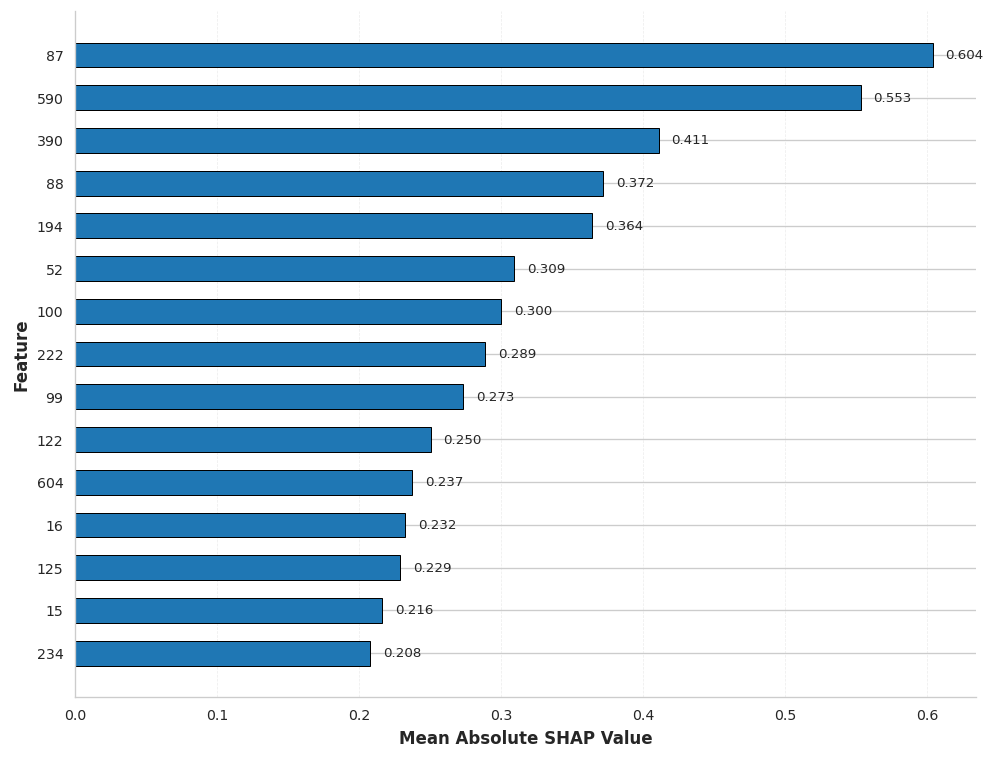


✓ Figure 1 completed:
  Figure_SHAP_Global_Importance_Q1.png
  Figure_SHAP_Global_Importance_Q1.pdf


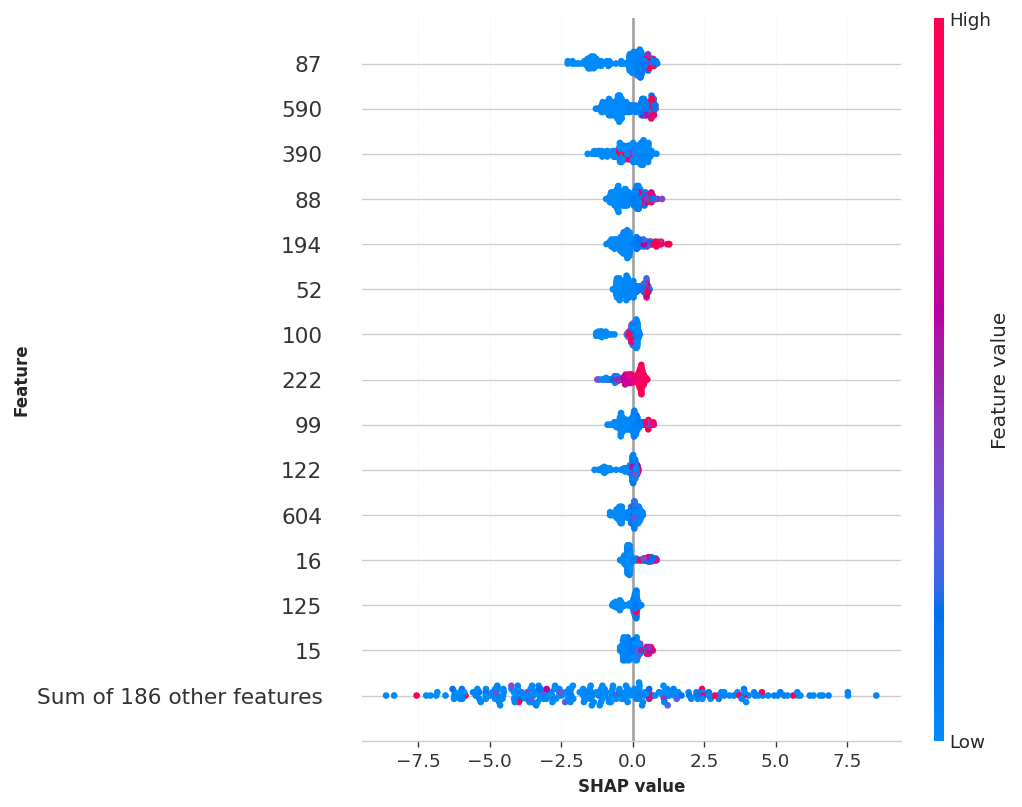


✓ Figure 2 completed:
  Figure_SHAP_Beeswarm_Q1.png
  Figure_SHAP_Beeswarm_Q1.pdf

Top two dependence features:
1. 87 (column 13)
2. 590 (column 198)

Generating dependence plot 1: 87


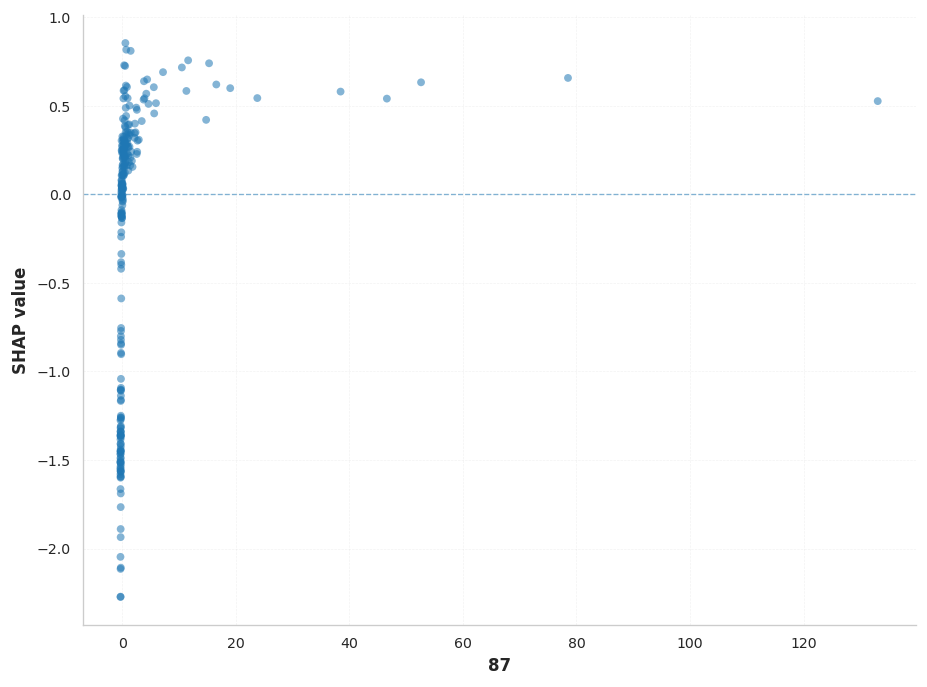

✓ Saved: Figure_SHAP_Dependence_1_Q1.png
✓ Saved: Figure_SHAP_Dependence_1_Q1.pdf

Generating dependence plot 2: 590


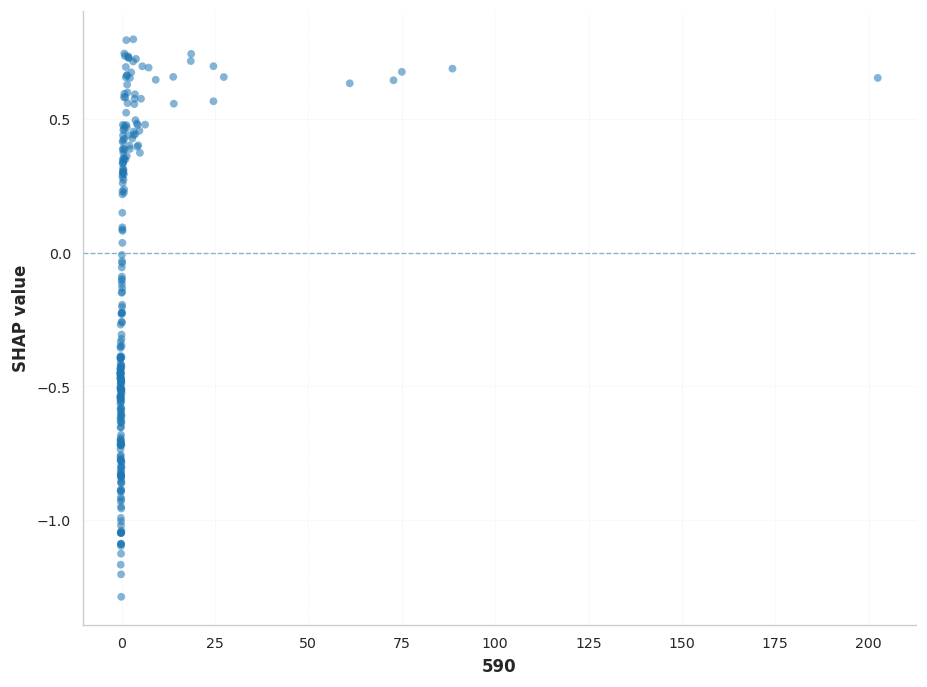

✓ Saved: Figure_SHAP_Dependence_2_Q1.png
✓ Saved: Figure_SHAP_Dependence_2_Q1.pdf

FINAL Q1 SHAP FIGURES COMPLETED

Generated:

1. Figure_SHAP_Global_Importance_Q1
2. Figure_SHAP_Beeswarm_Q1
3. Figure_SHAP_Dependence_1_Q1
4. Figure_SHAP_Dependence_2_Q1

Formats:
✓ 600-DPI PNG
✓ Vector PDF

No SHAP values were recalculated.



In [55]:
# ============================================================
# FINAL Q1-JOURNAL SHAP FIGURES
#
# Uses EXISTING SHAP values
# NO SHAP RECALCULATION
#
# Figures:
#   1. Global SHAP Feature Importance
#   2. SHAP Beeswarm
#   3. SHAP Dependence Plot — Top Feature
#   4. SHAP Dependence Plot — Second Feature
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc

print("=" * 75)
print("FINAL Q1-JOURNAL SHAP VISUALIZATION")
print("=" * 75)

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

assert "shap_values" in globals(), \
    "SHAP values are not available."

assert "X_explain_df" in globals(), \
    "X_explain_df is not available."

assert "shap_importance" in globals(), \
    "shap_importance is not available."

assert shap_values.shape == X_explain_df.shape, \
    f"Mismatch: {shap_values.shape} vs {X_explain_df.shape}"

print("SHAP matrix :", shap_values.shape)
print("Input matrix:", X_explain_df.shape)

# ============================================================
# 2. PUBLICATION FONT
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 12,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ============================================================
# 3. IDENTIFY FEATURE NAMES
# ============================================================

# Start with the columns actually used by SHAP
feature_names_final = list(X_explain_df.columns)

# Check whether another descriptive feature_names array exists
# and whether it actually contains useful names.

descriptive_names = None

if "feature_names" in globals():

    candidate_names = list(feature_names)

    if len(candidate_names) == X_explain_df.shape[1]:

        # Determine whether these are useful descriptive names
        numeric_count = 0

        for name in candidate_names:

            try:
                float(str(name))
                numeric_count += 1
            except:
                pass

        # Use them only if they are predominantly non-numeric
        if numeric_count < len(candidate_names) * 0.5:

            descriptive_names = [
                str(x) for x in candidate_names
            ]

if descriptive_names is not None:

    feature_names_final = descriptive_names

    print("✓ Descriptive feature names detected.")

else:

    print(
        "⚠ Descriptive feature names were not detected."
    )

    print(
        "  Current feature labels will be retained."
    )

# Make sure dataframe columns correspond to final names
X_plot = X_explain_df.copy()
X_plot.columns = feature_names_final

# ============================================================
# 4. REBUILD IMPORTANCE TABLE WITH FINAL NAMES
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance_final = pd.DataFrame({
    "Feature": feature_names_final,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_final = (
    shap_importance_final
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

# Save final table
shap_importance_final.to_csv(
    "SHAP_Global_Feature_Importance_Final.csv",
    index=False
)

print("\nTop 15 SHAP features:")
print(
    shap_importance_final.head(15).to_string(
        index=False
    )
)

# ============================================================
# 5. TOP 15 FEATURES
# ============================================================

TOP_N = 15

top15 = shap_importance_final.head(TOP_N)

# Reverse order for horizontal bar plot
top15_plot = top15.iloc[::-1].copy()

# ============================================================
# FIGURE 1
# GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.4, 6.4)
)

bars = ax.barh(
    np.arange(len(top15_plot)),
    top15_plot["Mean_Absolute_SHAP"].values,
    height=0.58,
    edgecolor="black",
    linewidth=0.6
)

ax.set_yticks(
    np.arange(len(top15_plot))
)

ax.set_yticklabels(
    top15_plot["Feature"].astype(str)
)

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------

max_value = top15_plot[
    "Mean_Absolute_SHAP"
].max()

for bar, value in zip(
    bars,
    top15_plot["Mean_Absolute_SHAP"]
):

    ax.text(
        value + max_value * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha="left",
        fontsize=8
    )

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Mean Absolute SHAP Value",
    fontweight="bold"
)

ax.set_ylabel(
    "Feature",
    fontweight="bold"
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.45,
    alpha=0.35
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Clean frame
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# No unnecessary title
# ------------------------------------------------------------

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Figure_SHAP_Global_Importance_Q1.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_SHAP_Global_Importance_Q1.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\n✓ Figure 1 completed:")
print("  Figure_SHAP_Global_Importance_Q1.png")
print("  Figure_SHAP_Global_Importance_Q1.pdf")


# ============================================================
# FIGURE 2
# SHAP BEESWARM — TOP 15
# ============================================================

# We create the SHAP Explanation using the final names.

try:

    import shap

    shap_explanation_final = shap.Explanation(
        values=np.asarray(
            shap_values,
            dtype=np.float32
        ),
        data=np.asarray(
            X_plot,
            dtype=np.float32
        ),
        feature_names=feature_names_final
    )

    plt.figure(
        figsize=(8.8, 6.8)
    )

    shap.plots.beeswarm(
        shap_explanation_final,
        max_display=15,
        show=False,
        plot_size=None
    )

    ax = plt.gca()

    # --------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------

    ax.set_xlabel(
        "SHAP value",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Feature",
        fontsize=10,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Remove automatic title
    # --------------------------------------------------------

    ax.set_title("")

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.4,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Clean borders
    # --------------------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    plt.savefig(
        "Figure_SHAP_Beeswarm_Q1.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.savefig(
        "Figure_SHAP_Beeswarm_Q1.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("\n✓ Figure 2 completed:")
    print("  Figure_SHAP_Beeswarm_Q1.png")
    print("  Figure_SHAP_Beeswarm_Q1.pdf")

except Exception as e:

    print("\n❌ Beeswarm generation failed:")
    print(e)


# ============================================================
# 6. FIND TOP TWO FEATURE POSITIONS
# ============================================================

top2_features = (
    shap_importance_final
    .head(2)["Feature"]
    .tolist()
)

feature_positions = []

for feature in top2_features:

    position = feature_names_final.index(
        feature
    )

    feature_positions.append(position)

print("\nTop two dependence features:")

for i, feature in enumerate(
    top2_features,
    start=1
):

    print(
        f"{i}. {feature} "
        f"(column {feature_positions[i-1]})"
    )


# ============================================================
# FIGURES 3 & 4
# SHAP DEPENDENCE PLOTS
# ============================================================

for plot_number, (
    feature,
    feature_position
) in enumerate(
    zip(
        top2_features,
        feature_positions
    ),
    start=1
):

    print(
        f"\nGenerating dependence plot "
        f"{plot_number}: {feature}"
    )

    # --------------------------------------------------------
    # Extract feature values
    # --------------------------------------------------------

    x_values = X_plot.iloc[
        :,
        feature_position
    ].values

    y_values = shap_values[
        :,
        feature_position
    ]

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(7.8, 5.8)
    )

    ax.scatter(
        x_values,
        y_values,
        s=22,
        alpha=0.55,
        edgecolors="none"
    )

    # --------------------------------------------------------
    # Zero reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.8,
        alpha=0.55
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel(
        str(feature),
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "SHAP value",
        fontsize=10,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Remove title
    # --------------------------------------------------------

    ax.set_title("")

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        linestyle="--",
        linewidth=0.4,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    # --------------------------------------------------------
    # Clean borders
    # --------------------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    plt.tight_layout()

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    png_name = (
        f"Figure_SHAP_Dependence_{plot_number}_Q1.png"
    )

    pdf_name = (
        f"Figure_SHAP_Dependence_{plot_number}_Q1.pdf"
    )

    plt.savefig(
        png_name,
        dpi=600,
        bbox_inches="tight"
    )

    plt.savefig(
        pdf_name,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"✓ Saved: {png_name}")
    print(f"✓ Saved: {pdf_name}")


# ============================================================
# FINAL MEMORY CLEANUP
# ============================================================

gc.collect()

print("\n" + "=" * 75)
print("FINAL Q1 SHAP FIGURES COMPLETED")
print("=" * 75)

print("""
Generated:

1. Figure_SHAP_Global_Importance_Q1
2. Figure_SHAP_Beeswarm_Q1
3. Figure_SHAP_Dependence_1_Q1
4. Figure_SHAP_Dependence_2_Q1

Formats:
✓ 600-DPI PNG
✓ Vector PDF

No SHAP values were recalculated.
""")

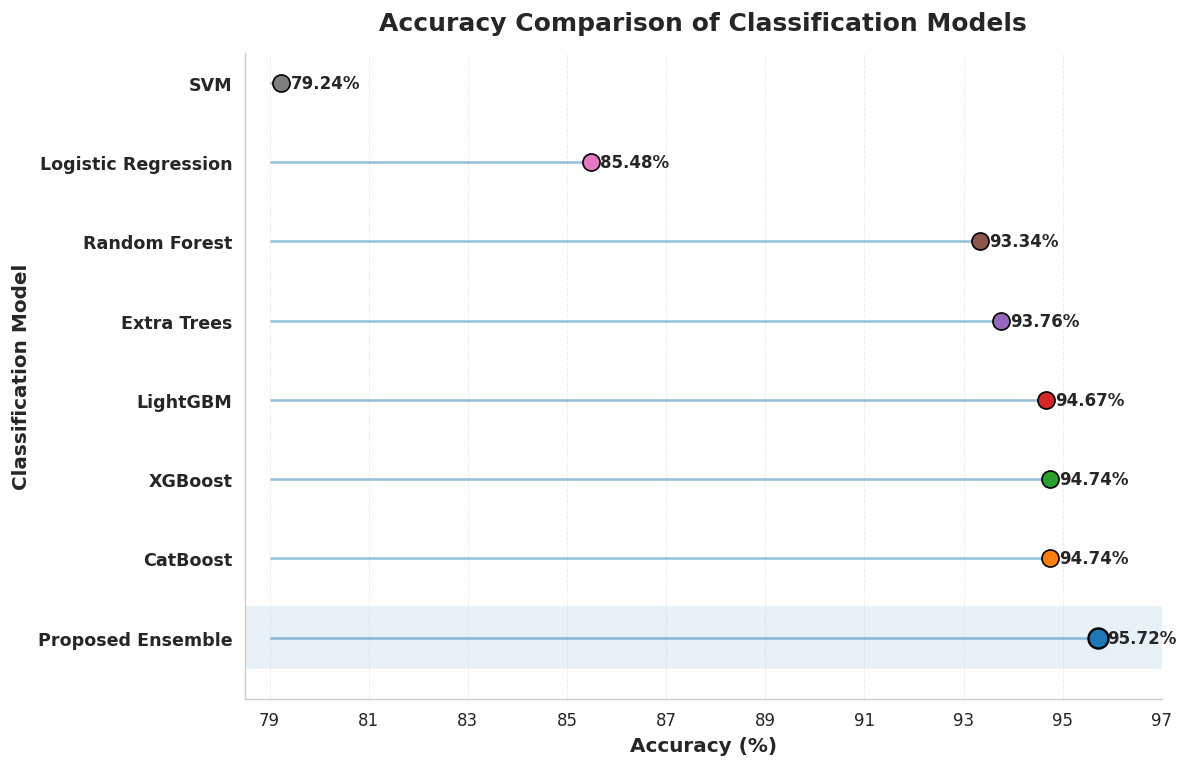

ACCURACY COMPARISON FIGURE GENERATED
Models included : 8
Best model      : Proposed Ensemble
Best accuracy   : 95.72%

Saved files:
✓ Figure_Accuracy_Comparison_All_Models.png
✓ Figure_Accuracy_Comparison_All_Models.pdf
✓ 600 DPI PNG
✓ Vector PDF
✓ All 8 models included


In [56]:
# ============================================================
# Q1 JOURNAL-LEVEL FIGURE
# ACCURACY COMPARISON — ALL CLASSIFICATION MODELS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ------------------------------------------------------------
# Publication-safe font
# ------------------------------------------------------------
rcParams["font.family"] = "DejaVu Sans"
rcParams["font.size"] = 10

# ------------------------------------------------------------
# FINAL RESULTS — EXACT VALUES FROM YOUR FINAL TABLE
# ------------------------------------------------------------

models = [
    "Proposed Ensemble",
    "XGBoost",
    "CatBoost",
    "LightGBM",
    "Extra Trees",
    "Random Forest",
    "Logistic Regression",
    "SVM"
]

accuracy = np.array([
    95.72,
    94.74,
    94.74,
    94.67,
    93.76,
    93.34,
    85.48,
    79.24
])

# ------------------------------------------------------------
# Sort from highest to lowest
# ------------------------------------------------------------

order = np.argsort(accuracy)[::-1]

models_sorted = [models[i] for i in order]
accuracy_sorted = accuracy[order]

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

y_pos = np.arange(len(models_sorted))

# ------------------------------------------------------------
# Highlight Proposed Ensemble
# ------------------------------------------------------------

for i, (model, value) in enumerate(
    zip(models_sorted, accuracy_sorted)
):

    if model == "Proposed Ensemble":

        ax.axhspan(
            i - 0.40,
            i + 0.40,
            alpha=0.10,
            zorder=0
        )

# ------------------------------------------------------------
# Horizontal reference lines
# ------------------------------------------------------------

for i in y_pos:

    ax.hlines(
        y=i,
        xmin=79.0,
        xmax=accuracy_sorted[i],
        linewidth=1.6,
        alpha=0.45,
        zorder=1
    )

# ------------------------------------------------------------
# Points
# ------------------------------------------------------------

for i, (model, value) in enumerate(
    zip(models_sorted, accuracy_sorted)
):

    if model == "Proposed Ensemble":

        ax.scatter(
            value,
            i,
            s=145,
            marker="o",
            edgecolor="black",
            linewidth=1.4,
            zorder=3
        )

    else:

        ax.scatter(
            value,
            i,
            s=105,
            marker="o",
            edgecolor="black",
            linewidth=1.0,
            zorder=3
        )

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------

for i, value in enumerate(accuracy_sorted):

    ax.text(
        value + 0.18,
        i,
        f"{value:.2f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(y_pos)

ax.set_yticklabels(
    models_sorted,
    fontsize=10.5,
    fontweight="bold"
)

ax.set_ylabel(
    "Classification Model",
    fontsize=12,
    fontweight="bold"
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xlabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(
    78.5,
    97.0
)

ax.set_xticks(
    np.arange(79, 98, 2)
)

ax.tick_params(
    axis="x",
    labelsize=10
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

ax.grid(
    axis="y",
    visible=False
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Accuracy Comparison of Classification Models",
    fontsize=15,
    fontweight="bold",
    pad=14
)

# ------------------------------------------------------------
# Spines
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# Tick direction
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="both",
    length=4
)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save high-resolution files
# ------------------------------------------------------------

plt.savefig(
    "Figure_Accuracy_Comparison_All_Models.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_Accuracy_Comparison_All_Models.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print("=" * 70)
print("ACCURACY COMPARISON FIGURE GENERATED")
print("=" * 70)

print("Models included :", len(models_sorted))
print("Best model      :", models_sorted[0])
print("Best accuracy   :", f"{accuracy_sorted[0]:.2f}%")

print("\nSaved files:")
print("✓ Figure_Accuracy_Comparison_All_Models.png")
print("✓ Figure_Accuracy_Comparison_All_Models.pdf")
print("✓ 600 DPI PNG")
print("✓ Vector PDF")
print("✓ All 8 models included")
print("=" * 70)

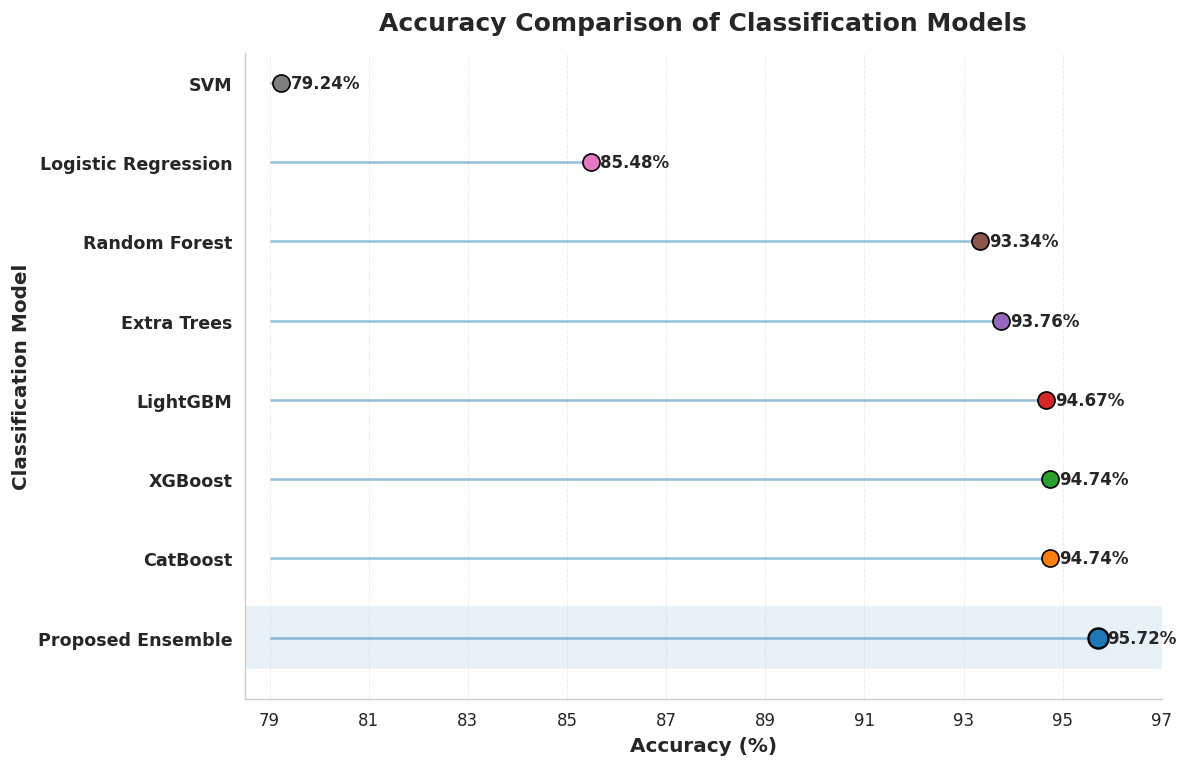

ACCURACY COMPARISON FIGURE GENERATED
Models included : 8
Best model      : Proposed Ensemble
Best accuracy   : 95.72%

Saved files:
✓ Figure_Accuracy_Comparison_All_Models.png
✓ Figure_Accuracy_Comparison_All_Models.pdf
✓ 600 DPI PNG
✓ Vector PDF
✓ All 8 models included


In [57]:
# ============================================================
# Q1 JOURNAL-LEVEL FIGURE
# ACCURACY COMPARISON — ALL CLASSIFICATION MODELS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ------------------------------------------------------------
# Publication-safe font
# ------------------------------------------------------------
rcParams["font.family"] = "DejaVu Sans"
rcParams["font.size"] = 10

# ------------------------------------------------------------
# FINAL RESULTS — EXACT VALUES FROM YOUR FINAL TABLE
# ------------------------------------------------------------

models = [
    "Proposed Ensemble",
    "XGBoost",
    "CatBoost",
    "LightGBM",
    "Extra Trees",
    "Random Forest",
    "Logistic Regression",
    "SVM"
]

accuracy = np.array([
    95.72,
    94.74,
    94.74,
    94.67,
    93.76,
    93.34,
    85.48,
    79.24
])

# ------------------------------------------------------------
# Sort from highest to lowest
# ------------------------------------------------------------

order = np.argsort(accuracy)[::-1]

models_sorted = [models[i] for i in order]
accuracy_sorted = accuracy[order]

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

y_pos = np.arange(len(models_sorted))

# ------------------------------------------------------------
# Highlight Proposed Ensemble
# ------------------------------------------------------------

for i, (model, value) in enumerate(
    zip(models_sorted, accuracy_sorted)
):

    if model == "Proposed Ensemble":

        ax.axhspan(
            i - 0.40,
            i + 0.40,
            alpha=0.10,
            zorder=0
        )

# ------------------------------------------------------------
# Horizontal reference lines
# ------------------------------------------------------------

for i in y_pos:

    ax.hlines(
        y=i,
        xmin=79.0,
        xmax=accuracy_sorted[i],
        linewidth=1.6,
        alpha=0.45,
        zorder=1
    )

# ------------------------------------------------------------
# Points
# ------------------------------------------------------------

for i, (model, value) in enumerate(
    zip(models_sorted, accuracy_sorted)
):

    if model == "Proposed Ensemble":

        ax.scatter(
            value,
            i,
            s=145,
            marker="o",
            edgecolor="black",
            linewidth=1.4,
            zorder=3
        )

    else:

        ax.scatter(
            value,
            i,
            s=105,
            marker="o",
            edgecolor="black",
            linewidth=1.0,
            zorder=3
        )

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------

for i, value in enumerate(accuracy_sorted):

    ax.text(
        value + 0.18,
        i,
        f"{value:.2f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(y_pos)

ax.set_yticklabels(
    models_sorted,
    fontsize=10.5,
    fontweight="bold"
)

ax.set_ylabel(
    "Classification Model",
    fontsize=12,
    fontweight="bold"
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xlabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(
    78.5,
    97.0
)

ax.set_xticks(
    np.arange(79, 98, 2)
)

ax.tick_params(
    axis="x",
    labelsize=10
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

ax.grid(
    axis="y",
    visible=False
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Accuracy Comparison of Classification Models",
    fontsize=15,
    fontweight="bold",
    pad=14
)

# ------------------------------------------------------------
# Spines
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# Tick direction
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="both",
    length=4
)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save high-resolution files
# ------------------------------------------------------------

plt.savefig(
    "Figure_Accuracy_Comparison_All_Models.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_Accuracy_Comparison_All_Models.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print("=" * 70)
print("ACCURACY COMPARISON FIGURE GENERATED")
print("=" * 70)

print("Models included :", len(models_sorted))
print("Best model      :", models_sorted[0])
print("Best accuracy   :", f"{accuracy_sorted[0]:.2f}%")

print("\nSaved files:")
print("✓ Figure_Accuracy_Comparison_All_Models.png")
print("✓ Figure_Accuracy_Comparison_All_Models.pdf")
print("✓ 600 DPI PNG")
print("✓ Vector PDF")
print("✓ All 8 models included")
print("=" * 70)

In [65]:
# =============================================================================
# RECOVER THE RAW EEG WINDOW CORRESPONDING TO TEST SAMPLE 789
# =============================================================================

from sklearn.model_selection import train_test_split
import numpy as np

# -------------------------------------------------------------------------
# IMPORTANT:
# Use the ORIGINAL labels corresponding to `signals`
# -------------------------------------------------------------------------

print("signals shape:", signals.shape)
print("labels shape :", labels.shape)

# -------------------------------------------------------------------------
# Recreate the exact 70/15/15 stratified split
# -------------------------------------------------------------------------

SEED = 42   # <-- MUST be the same seed used in your original split

all_indices = np.arange(len(signals))

train_idx, temp_idx, y_train_recreated, y_temp_recreated = train_test_split(
    all_indices,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

val_idx, test_idx, y_val_recreated, y_test_recreated = train_test_split(
    temp_idx,
    y_temp_recreated,
    test_size=0.50,
    stratify=y_temp_recreated,
    random_state=SEED
)

print("\nRecreated split:")
print("Train:", len(train_idx))
print("Val  :", len(val_idx))
print("Test :", len(test_idx))

# -------------------------------------------------------------------------
# Check test sample 789
# -------------------------------------------------------------------------

selected_test_position = 789

original_signal_index = test_idx[selected_test_position]

raw_signal = signals[original_signal_index]

true_label_raw = int(labels[original_signal_index])

print("\n" + "=" * 80)
print("RAW EEG RECOVERY")
print("=" * 80)

print("Test position       :", selected_test_position)
print("Original EEG index  :", original_signal_index)
print("Raw EEG shape       :", raw_signal.shape)
print("True label          :", true_label_raw)

assert raw_signal.shape == (18, 2048)

signals shape: (9505, 18, 2048)
labels shape : (9505,)

Recreated split:
Train: 6653
Val  : 1426
Test : 1426

RAW EEG RECOVERY
Test position       : 789
Original EEG index  : 6213
Raw EEG shape       : (18, 2048)
True label          : 1


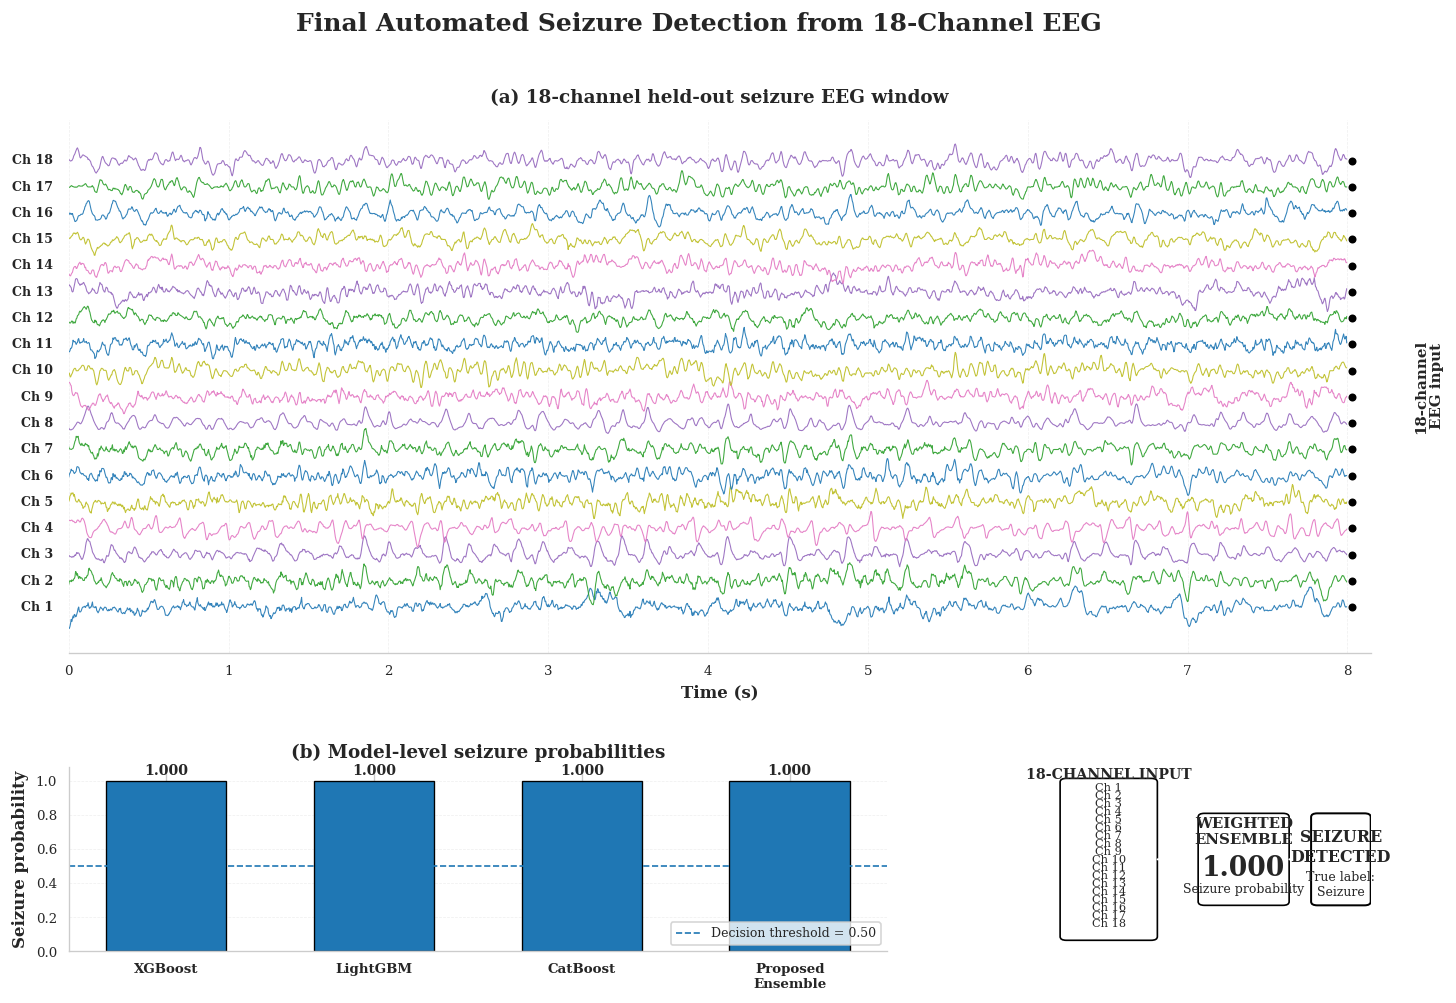

FIGURE 9 — FINAL 18-CHANNEL SEIZURE DETECTION
Test position       : 789
Original EEG index  : 6213
EEG shape           : (18, 2048)
True label          : 1
XGBoost             : 0.9999
LightGBM            : 1.0000
CatBoost            : 1.0000
Ensemble            : 1.0000
Weights             : (np.float64(0.1), np.float64(0.8), np.float64(0.09999999999999998))
Final decision      : SEIZURE DETECTED

PNG: /kaggle/working/Fig_9_18Channel_Final_Seizure_Detection.png
PDF: /kaggle/working/Fig_9_18Channel_Final_Seizure_Detection.pdf


In [67]:
# =============================================================================
# FIGURE 9 — 18-CHANNEL EEG TO FINAL SEIZURE DETECTION
# Q1-JOURNAL-STYLE VERSION
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# -----------------------------------------------------------------------------
# EXACT TEST SAMPLE
# -----------------------------------------------------------------------------

selected_test_position = 789
original_signal_index = test_idx[selected_test_position]

signal = signals[original_signal_index]
true_label = int(labels[original_signal_index])

# -----------------------------------------------------------------------------
# MODEL PROBABILITIES
# -----------------------------------------------------------------------------

prob_xgb = float(xgb_test[selected_test_position])
prob_lgb = float(lgb_test[selected_test_position])
prob_cat = float(cat_test[selected_test_position])
prob_ensemble = float(ensemble_prob[selected_test_position])

final_prediction = int(prob_ensemble >= 0.50)

# Exact ensemble weights
wx, wl, wc = best_weights

# -----------------------------------------------------------------------------
# VALIDATION
# -----------------------------------------------------------------------------

assert signal.shape == (18, 2048)
assert true_label == 1
assert final_prediction == 1

# -----------------------------------------------------------------------------
# TIME AXIS
# -----------------------------------------------------------------------------

FS = 256
time = np.arange(2048) / FS

# -----------------------------------------------------------------------------
# VISUALIZATION-ONLY NORMALIZATION
# -----------------------------------------------------------------------------

signal_vis = signal.astype(np.float64).copy()

for ch in range(18):

    median = np.median(signal_vis[ch])

    q1 = np.percentile(signal_vis[ch], 25)
    q3 = np.percentile(signal_vis[ch], 75)

    iqr = q3 - q1

    if iqr > 1e-12:
        signal_vis[ch] = (
            signal_vis[ch] - median
        ) / iqr
    else:
        signal_vis[ch] = signal_vis[ch] - median

# Channel separation
offset = 4.5

# -----------------------------------------------------------------------------
# JOURNAL FONT SETTINGS
# -----------------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# =============================================================================
# MAIN FIGURE
# =============================================================================

fig = plt.figure(figsize=(14, 9))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[4.2, 1.45],
    width_ratios=[3.0, 1.15],
    hspace=0.32,
    wspace=0.30
)

# =============================================================================
# PANEL (a): 18-CHANNEL EEG
# =============================================================================

ax1 = fig.add_subplot(gs[0, :])

for ch in range(18):

    y_plot = signal_vis[ch] + ch * offset

    ax1.plot(
        time,
        y_plot,
        linewidth=0.65,
        alpha=0.90
    )

    # Channel label
    ax1.text(
        -0.012,
        ch * offset,
        f"Ch {ch+1}",
        transform=ax1.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=7.5,
        fontweight="bold"
    )

    # Small right-side marker showing this channel is part of
    # the joint 18-channel input.
    ax1.plot(
        [time[-1] + 0.03],
        [ch * offset],
        marker="o",
        markersize=3.8,
        markerfacecolor="black",
        markeredgecolor="black",
        clip_on=False
    )

# -------------------------------------------------------------------------
# Overall bracket / annotation for all 18 channels
# -------------------------------------------------------------------------

ax1.annotate(
    "",
    xy=(1.015, 0.03),
    xytext=(1.015, 0.97),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="<->",
        linewidth=1.0
    )
)

ax1.text(
    1.045,
    0.50,
    "18-channel\nEEG input",
    transform=ax1.transAxes,
    rotation=90,
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold"
)

ax1.set_xlim(
    time[0],
    time[-1] + 0.15
)

ax1.set_yticks([])

ax1.set_xlabel(
    "Time (s)",
    fontweight="bold"
)

ax1.set_title(
    "(a) 18-channel held-out seizure EEG window",
    fontweight="bold",
    pad=10
)

ax1.grid(
    axis="x",
    linestyle="--",
    linewidth=0.45,
    alpha=0.30
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_visible(False)

# =============================================================================
# PANEL (b): MODEL PREDICTION PROBABILITIES
# =============================================================================

ax2 = fig.add_subplot(gs[1, 0])

model_names = [
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "Proposed\nEnsemble"
]

probabilities = [
    prob_xgb,
    prob_lgb,
    prob_cat,
    prob_ensemble
]

bars = ax2.bar(
    np.arange(4),
    probabilities,
    width=0.58,
    edgecolor="black",
    linewidth=0.8
)

# Decision threshold
ax2.axhline(
    0.50,
    linestyle="--",
    linewidth=1.0,
    label="Decision threshold = 0.50"
)

ax2.set_ylim(0, 1.08)

ax2.set_ylabel(
    "Seizure probability",
    fontweight="bold"
)

ax2.set_title(
    "(b) Model-level seizure probabilities",
    fontweight="bold"
)

ax2.set_xticks(np.arange(4))
ax2.set_xticklabels(
    model_names,
    fontweight="bold"
)

ax2.grid(
    axis="y",
    linestyle="--",
    linewidth=0.45,
    alpha=0.30
)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

for bar, value in zip(bars, probabilities):

    ax2.text(
        bar.get_x() + bar.get_width()/2,
        min(value + 0.025, 1.02),
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold"
    )

ax2.legend(
    fontsize=7.5,
    loc="lower right",
    frameon=True
)

# =============================================================================
# PANEL (c): 18 CHANNELS → ENSEMBLE → FINAL DETECTION
# =============================================================================

ax3 = fig.add_subplot(gs[1, 1])

ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1)
ax3.axis("off")

# -------------------------------------------------------------------------
# 18 CHANNEL INPUT BOX
# -------------------------------------------------------------------------

input_box = FancyBboxPatch(
    (0.03, 0.08),
    0.27,
    0.84,
    boxstyle="round,pad=0.02",
    linewidth=1.0,
    edgecolor="black",
    facecolor="white"
)

ax3.add_patch(input_box)

ax3.text(
    0.165,
    0.96,
    "18-CHANNEL INPUT",
    ha="center",
    va="center",
    fontsize=8.5,
    fontweight="bold"
)

# Display Ch1 to Ch18
for ch in range(18):

    y = 0.89 - ch * 0.0435

    ax3.text(
        0.165,
        y,
        f"Ch {ch+1}",
        ha="center",
        va="center",
        fontsize=6.8
    )

# -------------------------------------------------------------------------
# ARROW TO ENSEMBLE
# -------------------------------------------------------------------------

arrow1 = FancyArrowPatch(
    (0.31, 0.50),
    (0.47, 0.50),
    arrowstyle="->",
    mutation_scale=13,
    linewidth=1.2
)

ax3.add_patch(arrow1)

# -------------------------------------------------------------------------
# ENSEMBLE BOX
# -------------------------------------------------------------------------

ensemble_box = FancyBboxPatch(
    (0.47, 0.27),
    0.25,
    0.46,
    boxstyle="round,pad=0.02",
    linewidth=1.0,
    edgecolor="black",
    facecolor="white"
)

ax3.add_patch(ensemble_box)

ax3.text(
    0.595,
    0.65,
    "WEIGHTED\nENSEMBLE",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold"
)

ax3.text(
    0.595,
    0.45,
    f"{prob_ensemble:.3f}",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax3.text(
    0.595,
    0.34,
    "Seizure probability",
    ha="center",
    va="center",
    fontsize=7.5
)

# -------------------------------------------------------------------------
# ARROW TO FINAL DECISION
# -------------------------------------------------------------------------

arrow2 = FancyArrowPatch(
    (0.73, 0.50),
    (0.84, 0.50),
    arrowstyle="->",
    mutation_scale=13,
    linewidth=1.2
)

ax3.add_patch(arrow2)

# -------------------------------------------------------------------------
# FINAL DETECTION BOX
# -------------------------------------------------------------------------

decision_box = FancyBboxPatch(
    (0.83, 0.27),
    0.15,
    0.46,
    boxstyle="round,pad=0.02",
    linewidth=1.2,
    edgecolor="black",
    facecolor="white"
)

ax3.add_patch(decision_box)

ax3.text(
    0.905,
    0.62,
    "SEIZURE",
    ha="center",
    va="center",
    fontsize=9.5,
    fontweight="bold"
)

ax3.text(
    0.905,
    0.51,
    "DETECTED",
    ha="center",
    va="center",
    fontsize=9.5,
    fontweight="bold"
)

ax3.text(
    0.905,
    0.36,
    "True label:\nSeizure",
    ha="center",
    va="center",
    fontsize=7.5
)

# =============================================================================
# OVERALL TITLE
# =============================================================================

fig.suptitle(
    "Final Automated Seizure Detection from 18-Channel EEG",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

# =============================================================================
# SAVE
# =============================================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

png_path = (
    "/kaggle/working/"
    "Fig_9_18Channel_Final_Seizure_Detection.png"
)

pdf_path = (
    "/kaggle/working/"
    "Fig_9_18Channel_Final_Seizure_Detection.pdf"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

plt.close()

# =============================================================================
# FINAL INFORMATION
# =============================================================================

print("=" * 80)
print("FIGURE 9 — FINAL 18-CHANNEL SEIZURE DETECTION")
print("=" * 80)
print("Test position       :", selected_test_position)
print("Original EEG index  :", original_signal_index)
print("EEG shape           :", signal.shape)
print("True label          :", true_label)
print("XGBoost             :", f"{prob_xgb:.4f}")
print("LightGBM            :", f"{prob_lgb:.4f}")
print("CatBoost            :", f"{prob_cat:.4f}")
print("Ensemble            :", f"{prob_ensemble:.4f}")
print("Weights             :", best_weights)
print("Final decision      : SEIZURE DETECTED")
print()
print("PNG:", png_path)
print("PDF:", pdf_path)
print("=" * 80)